# Notebook 06 — Predecir si una síntesis cristaliza: un caso completo de ciencia de datos

**Proyecto:** ALCheMy · **Autor:** Rubén Serrano Nieto & AI Agent Pair · **Fecha:** 2026-08-28 / 30

---

### Cómo leer este cuaderno

Este cuaderno recorre **un problema de ciencia de datos de principio a fin**: desde
"¿qué pregunta de laboratorio quiero contestar?" hasta un modelo evaluado y un
análisis de qué variables químicas mandan. No es un script que entrena un modelo:
es el registro de por qué cada decisión se tomó como se tomó, incluidas las que
salieron mal.

Está estructurado según el **marco metodológico de 10 etapas** (Rollins, IBM), que
es el refinamiento más usado de **CRISP-DM** (*Cross-Industry Standard Process for
Data Mining*, 1999 — el estándar de facto de la industria, todavía hoy). Las dos
dicen lo mismo con distinto grano; la de 10 etapas separa mejor las primeras fases,
que es justo donde se juega un proyecto de investigación como este:

| Etapa (10 etapas) | Fase CRISP-DM | ¿Dónde está aquí? |
|---|---|---|
| 1. Comprensión del negocio | Business Understanding | §1 |
| 2. Enfoque analítico | Business Understanding | §2 |
| 3. Requisitos de datos | Data Understanding | §3 |
| 4. Recolección de datos | Data Understanding | §4 |
| 5. Comprensión de los datos | Data Understanding | §5 (EDA) |
| 6. Preparación de los datos | Data Preparation | §6 (ETL) |
| 7. Modelado | Modeling | §7 |
| 8. Evaluación | Evaluation | §8 |
| 9. Despliegue | Deployment | §9 |
| 10. Retroalimentación | *(cierra el ciclo)* | §10 |

**El ciclo es iterativo, no una escalera.** Este cuaderno ya ha dado dos vueltas
completas: la etapa 5 (EDA) descubrió incoherencias que obligaron a volver a la
etapa 4 (recolección), y la etapa 6 destapó 43 muestras duplicadas que obligaron a
revisar el etiquetado. Esas vueltas atrás están contadas donde ocurrieron, no
escondidas.

### Índice

**Ciclo del dato**
- §1 Comprensión del problema — qué pregunta de laboratorio, y qué la haría útil
- §2 Enfoque analítico — por qué clasificación y no regresión
- §3 Requisitos de datos — qué haría falta idealmente, y qué hay
- §4 Recolección — las dos vías de ingesta y las tablas de referencia química

**Entender y preparar**
- §5 Análisis exploratorio (EDA) — perfilado, ausentes, distribuciones, correlación, fugas
- §6 Preparación (ETL) — calidad, correcciones, exclusiones, la consulta final

**Modelar y evaluar**
- §7 Modelado — 10 familias de modelos con validación agrupada
- §8 Evaluación — métricas, matriz de confusión, interpretación con SHAP
- §9 Despliegue — cómo se usaría esto en el laboratorio
- §10 Retroalimentación — qué cierra el ciclo, y qué queda abierto

In [1]:
# ── Entorno ────────────────────────────────────────────────────────────────
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import psycopg2
from dotenv import load_dotenv

warnings.filterwarnings('ignore')

# Resolucion de ruta robusta: funciona desde la raiz del repo o desde notebooks/
env_path = '.env' if os.path.exists('.env') else os.path.join('..', '.env')
load_dotenv(env_path)

conn = psycopg2.connect(
    host=os.getenv('POSTGRES_HOST', 'localhost'),
    port=int(os.getenv('POSTGRES_PORT', 5432)),
    dbname=os.getenv('POSTGRES_DB', 'alchemy_db'),
    user=os.getenv('POSTGRES_USER'),
    password=os.getenv('POSTGRES_PASSWORD'),
)
q = lambda sql: pd.read_sql(sql, conn)

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 160)

# Paleta compartida con app/pxrd_explorer.py y app/pxrd_labeler.py, para que las
# figuras de todo el proyecto se lean como un mismo sistema visual.
C_AMOR, C_INC, C_CRYS, C_MEZ = '#e8a33d', '#7e57c2', '#1f7a8c', '#c0392b'
CLASS_COLORS = {'AMORFO': C_AMOR, 'INCIPIENTE': C_INC, 'CRISTALINO': C_CRYS, 'MEZCLA': C_MEZ}
CLASS_ORDER = ['AMORFO', 'INCIPIENTE', 'CRISTALINO']

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'font.size': 9})
sns.set_style('whitegrid', {'grid.alpha': 0.25})

print('Entorno listo. Base de datos:', os.getenv('POSTGRES_DB'))

Entorno listo. Base de datos: alchemy_db


---

# §1. Comprensión del problema

> *Etapa 1 — Business Understanding. La única etapa que no se puede automatizar, y
> la que decide si todo lo demás sirve para algo.*

### La pregunta, en el lenguaje del laboratorio

Sintetizar un MOF es caro en lo que menos sobra: **tiempo**. Una síntesis
solvotermal ocupa una estufa entre 24 y 72 horas, y el resultado sólo se conoce
al sacarla y medir el difractograma. La mayoría no cristaliza.

> **¿Se puede saber, *antes* de meter el reactor en la estufa, si esa combinación
> de metal, linker, disolvente, modulador y rampa térmica va a cristalizar?**

### Por qué esto no es una pregunta de curiosidad

Sirve para tres cosas concretas, en orden de valor:

1. **Descartar** condiciones condenadas al fracaso antes de gastar 48 h de estufa.
2. **Priorizar** el siguiente lote de una campaña de alto rendimiento (HTS): si
   caben 24 pocillos, llenarlos con los 24 candidatos más prometedores.
3. **Entender** — y esta es la de verdad importante en un contexto de
   investigación. Un modelo que predice bien pero no explica nada vale poco aquí;
   uno que dice *"la oxofilicidad del metal y la relación linker/metal son lo que
   manda"* es un resultado químico, comunicable y publicable, aunque acierte
   moderadamente.

### El criterio de éxito, fijado ANTES de mirar ningún resultado

Fijarlo después es engañarse: siempre se encuentra una métrica que hace que el
modelo parezca bueno.

- **Mínimo para ser útil:** batir de forma clara a la estrategia trivial de
  "predecir siempre la clase mayoritaria". Si no bate eso, el modelo no aporta
  información sobre la química, sólo reproduce el desequilibrio del histórico.
- **Deseable:** que las variables que el modelo considera importantes tengan
  sentido químico. Un modelo con buena métrica y variables importantes absurdas
  suele estar aprovechando una fuga de datos, no química.
- **Explícitamente NO buscamos** exactitud alta a cualquier precio. Con clases
  desequilibradas la exactitud es una métrica tramposa (§8.1).

---

# §2. Enfoque analítico

> *Etapa 2 — Analytic Approach. Traducir la pregunta del laboratorio a un tipo de
> problema estadístico. Elegir mal aquí no se arregla luego con más modelos.*

### El árbol de decisión

La pregunta determina la familia de técnicas:

| Si la pregunta es… | Entonces… |
|---|---|
| ¿A qué **categoría** pertenece? | **Clasificación supervisada** |
| ¿Qué **valor numérico** tomará? | Regresión supervisada |
| ¿Hay **grupos naturales** sin etiquetas? | Clustering (no supervisado) |
| ¿Puedo **resumir** muchas columnas? | Reducción de dimensionalidad (PCA…) |

### Por qué clasificación y no regresión

Es la decisión de diseño más importante del cuaderno, y podría haber ido al revés.
Existe un candidato razonable a variable continua: `amorphous_fraction_blank`, la
fracción de lo que dispersó la muestra que fue difusa en vez de picos de Bragg —
un número entre 0 y 1 que *parece* medir "cuán cristalino" es el material. Predecir
ese número sería una regresión.

**Se descartó por tres razones, en orden de peso:**

1. **La variable continua no es fiable en sus extremos.** Tiene un suelo de
   detección de ~0,02 (notebook 05 §7.5): por debajo, el número es ruido residual
   de la línea base, no señal. Una regresión trataría la diferencia entre 0,005 y
   0,015 como información real cuando ambos significan lo mismo — "nada medible".
   Y las medianas por clase (§5) muestran que la clase CRISTALINO vive entera en
   esa zona ciega.
2. **La decisión del laboratorio es categórica.** Rubén no decide "repetir esta
   síntesis" en función de si la fracción amorfa es 0,42 o 0,48; decide en función
   de si aquello cristalizó, cristalizó a medias, o no cristalizó. El modelo debe
   predecir la decisión que se va a tomar, no un número del que luego habría que
   inferirla.
3. **La verdad de referencia (*ground truth*) es un juicio humano categórico.** Las
   etiquetas de `pxrd_labels` son el veredicto de un químico mirando el
   difractograma, y ese veredicto integra cosas que ningún descriptor captura
   (forma del halo, posición de las reflexiones, si los picos son del producto o de
   un óxido). Convertir ese juicio en un número continuo para luego hacer regresión
   sería inventar precisión que la etiqueta no tiene.

**Conclusión:** clasificación supervisada multiclase, 3 clases
(AMORFO / INCIPIENTE / CRISTALINO).

### Dos problemas distintos que comparten tablas — y sólo uno interesa

Conviene separarlos porque es fácil confundirlos y celebrar el equivocado:

| | **(A) descriptores PXRD → clase** | **(B) condiciones de síntesis → clase** |
|---|---|---|
| Entrada | Los 29 números del difractograma | Metal, linker, T, rampa, L/M, moduladores |
| ¿Cuándo se conoce la entrada? | *Después* de sintetizar y medir | *Antes* de sintetizar |
| ¿Qué valida? | Que el pipeline de señal funciona | Química de la cristalización |
| Utilidad real | Casi ninguna: es circular | **Toda** |

El problema (A) es casi circular: esos descriptores se **diseñaron** en el notebook
05 precisamente para separar estas clases. Un acierto alto ahí valida el
procesamiento de señal, no descubre nada. **Este cuaderno ataca el problema (B).**

---

# §3. Requisitos de datos

> *Etapa 3 — Data Requirements. Qué haría falta idealmente, dicho antes de mirar
> qué hay, para que el hueco entre lo ideal y lo real quede visible.*

Para predecir cristalización a partir de las condiciones haría falta:

| Bloque | Ideal | Qué hay realmente |
|---|---|---|
| **Química del metal** | Identidad, estado de oxidación, radio iónico, dureza, oxofilicidad | ✅ Tablas de referencia (§4.2) |
| **Química del linker** | Geometría, denticidad, acidez, flexibilidad | ✅ Descriptores RDKit (§4.2) |
| **Estequiometría** | Concentración, relación linker/metal | ✅ En `synthesis_experiments` |
| **Proceso** | T, tiempo, rampas de calentamiento y enfriamiento | ✅ Parseado en notebook 01 |
| **Medio** | Disolventes y proporciones, moduladores | ✅ En mmol activos |
| **Etiqueta** | Veredicto experto sobre el difractograma | ✅ `pxrd_labels` |
| **pH real del medio** | Medido | ❌ **No se mide** — hueco conocido |
| **Presión autógena** | Medida | ❌ No se mide (estimable, roadmap §7.2) |
| **Pureza del reactivo por lote** | Trazada | ❌ No se traza |

Los tres huecos son reales y se declaran aquí en vez de descubrirlos al final. El
del **pH** es el más serio: en química de fosfonatos el pH controla el grado de
desprotonación del linker, que es lo que gobierna la coordinación. Su efecto entra
en el modelo sólo de forma indirecta, a través de los moduladores ácido/base
añadidos, que es una aproximación pobre pero no nula.

---

# §4. Recolección de datos

> *Etapa 4 — Data Collection. De dónde sale cada número, y qué hubo que construir
> porque no existía.*

### 4.1 El ciclo del dato en ALCheMy, de la libreta al modelo

Nada de esto empezó siendo una tabla. El recorrido completo:

```
 (1) FUENTES CRUDAS
     Excel maestro de síntesis        ~5.700 ficheros de instrumento
     (5 años de libretas)             (.xrdml .brml .txt .csv .xls .jpg)
              │                                    │
 (2) INGESTA   ▼                                    ▼
     notebook 01: renombrado,         parsers deterministas (contrato
     ingenieria estequiometrica       comun: header_metadata + raw_data)
     (uL -> mmol activos),                         │
     parseo de rampas termicas,                    │
     clave natural MD5, UPSERT                     │
              │                                    │
 (3) ALMACEN   ▼                                    ▼
     synthesis_experiments  ◄──FK──  characterization_measurements
     (1 fila / sintesis)              (1 fila / medida, JSONB + GIN)
              │                                    │
 (4) PROCESO   │                                    ▼
              │                        notebook 05: arPLS, separacion
              │                        de halo, deteccion de picos
              │                                    │
              │                                    ▼
              │                        pxrd_descriptors (29 numeros)
              │                                    │
              │                                    ▼
              │                        app/pxrd_labeler.py (juicio humano)
              │                                    │
              │                                    ▼
              │                        pxrd_labels  ◄── LA ETIQUETA (Y)
 (5) FEATURES  ▼
     element_properties + ion_properties + linker_properties   (§4.2)
              │
              ▼
     v_ml_features  ─────────── LAS CARACTERISTICAS (X)
              │
 (6) MODELO    ▼
     Este cuaderno: §5 EDA -> §6 ETL -> §7 modelos -> §8 evaluacion
```

**Punto clave del diseño:** `v_ml_features` es una **vista**, no una tabla. Si
mañana se corrige un radio iónico en `ion_properties`, la corrección se propaga
sola a todo el dataset. Una tabla materializada habría dejado una copia obsoleta
conviviendo con el original, que es la forma clásica de que dos análisis del mismo
proyecto den números distintos y nadie sepa por qué.

In [2]:
# Volumen de cada eslabon de la cadena
q('''
    SELECT 'synthesis_experiments  (sintesis)'      AS tabla, count(*) AS filas FROM synthesis_experiments
    UNION ALL SELECT 'characterization_measurements (medidas)', count(*) FROM characterization_measurements
    UNION ALL SELECT 'pxrd_descriptors      (senal -> numeros)', count(*) FROM pxrd_descriptors
    UNION ALL SELECT 'pxrd_labels           (juicio humano)', count(*) FROM pxrd_labels
    UNION ALL SELECT 'v_ml_features         (X del modelo)', count(*) FROM v_ml_features
''')

,tabla,filas
0,synthesis_experiments (sintesis),3204
1,characterization_measurements (medidas),3926
2,pxrd_descriptors (senal -> numeros),1874
3,pxrd_labels (juicio humano),4964
4,v_ml_features (X del modelo),2154


### 4.2 Lo que hubo que construir: la química como números

`metal_center` es texto: `'Ni'`, `'Zr'`, `'Hf'`… Un modelo no puede usar texto,
así que la salida obvia es *one-hot encoding*: una columna binaria por metal.

**Y sería un error.** One-hot trata `Zr` y `Hf` como categorías tan distintas entre
sí como `Zr` y `Ca`, cuando Zr y Hf son químicamente casi el mismo elemento (mismo
grupo, mismo estado de oxidación habitual, radios iónicos que difieren en 1 pm).
Con 20 metales muy desigualmente repartidos, el modelo no puede aprender nada sobre
un metal que aparece 4 veces… salvo que se le diga *en qué se parece* a los que
aparecen 500 veces.

La solución es **featurización química**: sustituir la etiqueta por las propiedades
físico-químicas que la hacen comportarse como se comporta.

| Tabla | Qué aporta | Detalle que importa |
|---|---|---|
| `element_properties` | Electronegatividad, dureza, polarizabilidad, oxofilicidad | 20 metales |
| `ion_properties` | Radio de Shannon, carga/radio | Depende del **estado de oxidación**, no sólo del elemento |
| `metal_source_oxidation_state` | Estado de oxidación real | Derivado de la **fórmula del precursor** |
| `linker_properties` | Denticidad, protones ácidos, geometría, flexibilidad | 6 linkers = 3 esqueletos × 2 protecciones |

**El estado de oxidación sale de la fórmula del precursor, no del "más común del
elemento".** Es un detalle que parece pedante y no lo es: este laboratorio usa
Fe(II) y Fe(III), Ce(III) y Ce(IV), y asignar "el más común" habría metido un error
sistemático justo en los metales donde más importa. `FeCl₃·6H₂O` → Fe³⁺;
`FeCl₂·4H₂O` → Fe²⁺.

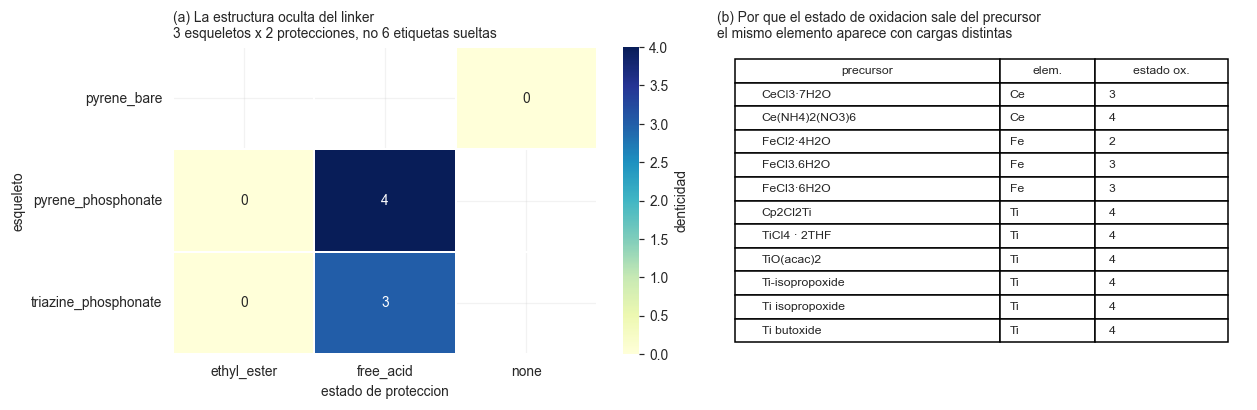

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.8))

# (a) Los 6 linkers no son 6 categorias: son 3 esqueletos x 2 estados de proteccion
lp = q('SELECT * FROM linker_properties ORDER BY scaffold, protection_state')
piv = lp.pivot_table(index='scaffold', columns='protection_state',
                     values='denticity', aggfunc='first')
sns.heatmap(piv, annot=True, fmt='.0f', cmap='YlGnBu', cbar_kws={'label': 'denticidad'},
            ax=axes[0], linewidths=1, linecolor='white')
axes[0].set_title('(a) La estructura oculta del linker\n3 esqueletos x 2 protecciones, no 6 etiquetas sueltas',
                  fontsize=9, loc='left')
axes[0].set_xlabel('estado de proteccion'); axes[0].set_ylabel('esqueleto')

# (b) Fe y Ce: el mismo elemento con dos estados de oxidacion reales en el corpus
mso = q('''SELECT metal_source, symbol, oxidation_state FROM metal_source_oxidation_state
           WHERE symbol IN ('Fe','Ce','Ti') AND oxidation_state IS NOT NULL
           ORDER BY symbol, oxidation_state''')
axes[1].axis('off')
axes[1].set_title('(b) Por que el estado de oxidacion sale del precursor\n'
                  'el mismo elemento aparece con cargas distintas', fontsize=9, loc='left')
tbl = axes[1].table(cellText=mso.values, colLabels=['precursor', 'elem.', 'estado ox.'],
                    loc='center', cellLoc='left', colWidths=[0.5, 0.18, 0.25])
tbl.auto_set_font_size(False); tbl.set_fontsize(8); tbl.scale(1, 1.35)
fig.tight_layout(); plt.show()

---

# §5. Análisis exploratorio de los datos (EDA)

> *Etapa 5 — Data Understanding. Mirar los datos antes de modelarlos. Es la etapa
> que más veces manda de vuelta a la anterior, y aquí lo hizo dos veces.*

Cargamos el conjunto de trabajo. La consulta ya incorpora las decisiones de
preparación que se justifican en §6 — se adelanta aquí porque explorar un conjunto
distinto del que se va a modelar es explorar otra cosa.

In [4]:
TRAINING_QUERY = '''
    SELECT v.*,
           CASE WHEN lc.label_value = 'MEZCLA' THEN 'CRISTALINO'
                ELSE lc.label_value END                      AS ml_class
      FROM v_ml_features v
      JOIN characterization_measurements cm ON cm.sample_code = v.sample_code
      JOIN pxrd_labels lc ON lc.measurement_id = cm.measurement_id
                         AND lc.label_type = 'crystallinity_class'
      LEFT JOIN pxrd_labels ex ON ex.measurement_id = cm.measurement_id
                              AND ex.label_type = 'ml_include'
                              AND ex.label_value = 'NO'
     WHERE lc.label_value <> 'SIN_MUESTRA'
       AND ex.measurement_id IS NULL
'''
df = q(TRAINING_QUERY)
print('Dimensiones:', df.shape[0], 'filas x', df.shape[1], 'columnas')
print('sample_code distintos:', df['sample_code'].nunique(), '(una fila por muestra)')
df.head(3)

Dimensiones: 1724 filas x 38 columnas
sample_code distintos: 1724 (una fila por muestra)


,sample_code,hts_number,synthesis_date,metal_center,linker,metal_source,electronegativity_pauling,electronegativity_allen,absolute_hardness_ev,oxophilicity_kepp,polarizability_a3,oxidation_state,shannon_radius_pm,charge_over_radius,metal_source_is_consistent,scaffold,protection_state,denticity,n_acidic_protons,max_donor_distance_a,n_rotatable_bonds,metal_conc_m,lm_ratio,temp_target_c,time_hours,heating_rate_c_min,cooling_rate_c_min,total_volume_ml,reactor_volume_ml,fill_fraction,frac_h2o,frac_meoh,frac_etoh,frac_dmf,mod_carboxylic_mmol,mod_strong_acid_mmol,mod_base_mmol,ml_class
0,RS1883,N/A,2024-04-19,Co,H8ptp,CoCl2·6H2O,1.88,10.86,3.609377,0.4,0.055,2.0,88.5,0.022599,True,pyrene_phosphonate,free_acid,4.0,8,9.36,4.0,0.03,0.5,175.0,0.5,30.0,11.5,15.0,30.0,0.5,0.333333,0.0,0.666667,0.0,0.0,0.0,0.0,CRISTALINO
1,RS1884,N/A,2024-04-19,Co,H8ptp,CoCl2·6H2O,1.88,10.86,3.609377,0.4,0.055,2.0,88.5,0.022599,True,pyrene_phosphonate,free_acid,4.0,8,9.36,4.0,0.03,0.5,175.0,0.5,30.0,11.5,15.0,30.0,0.5,0.333333,0.0,0.666667,0.0,0.0,0.0,0.0,CRISTALINO
2,RS1885,N/A,2024-04-19,Co,H8ptp,CoCl2,1.88,10.86,3.609377,0.4,0.055,2.0,88.5,0.022599,True,pyrene_phosphonate,free_acid,4.0,8,9.36,4.0,0.03,0.5,175.0,0.5,30.0,11.5,15.0,30.0,0.5,0.333333,0.0,0.666667,0.0,0.0,0.0,0.0,CRISTALINO


### 5.1 Perfilado: qué tipo de cosa es cada columna

El primer paso de todo EDA es aburrido y no se puede saltar: para cada columna, qué
tipo tiene, cuántos ausentes, cuántos valores distintos. Es donde aparecen los
problemas que luego cuestan horas.

In [5]:
def perfilar(frame):
    '''Perfil columna a columna: tipo, ausentes, cardinalidad y muestra de valores.'''
    filas = []
    for col in frame.columns:
        s = frame[col]
        filas.append({
            'columna': col,
            'tipo': str(s.dtype),
            'no nulos': s.notna().sum(),
            'nulos': s.isna().sum(),
            'nulos %': round(s.isna().mean() * 100, 2),
            'distintos': s.nunique(),
            'ejemplo': ', '.join(map(str, s.dropna().unique()[:3]))[:46],
        })
    return pd.DataFrame(filas)

perfil = perfilar(df)
perfil

,columna,tipo,no nulos,nulos,nulos %,distintos,ejemplo
0,sample_code,object,1724,0,0.00,1724,"RS1883, RS1884, RS1885"
1,hts_number,object,1724,0,0.00,70,"N/A, C#72, C#69"
2,synthesis_date,object,1724,0,0.00,131,"2024-04-19, 2024-07-08, 2024-08-06"
3,metal_center,object,1724,0,0.00,20,"Co, Ca, Ni"
4,linker,object,1724,0,0.00,5,"H8ptp, Et8ptp, H6ttbmp"
5,metal_source,object,1724,0,0.00,44,"CoCl2·6H2O, CoCl2, Ca(NO3)2·4H2O"
6,electronegativity_pauling,float64,1723,1,0.06,18,"1.88, 1.0, 1.91"
7,electronegativity_allen,float64,1681,43,2.49,15,"10.86, 6.1129999999999995, 11.13"
8,absolute_hardness_ev,float64,1570,154,8.93,17,"3.60937677, 3.044302735, 3.2419390000000003"
9,oxophilicity_kepp,float64,1719,5,0.29,7,"0.4, 0.3, 0.2"


**Dos cosas saltan del perfil**, y las dos cambian el modelo:

1. **`metal_source_is_consistent` tiene un único valor distinto.** Es una columna
   constante: desde que se corrigieron las 6 discrepancias metal/precursor (§6.1),
   *todas* las filas valen `True`. Una columna constante aporta cero información y
   hay que quitarla — no es un error, es la huella de un problema ya resuelto.
2. **Los ausentes no están repartidos al azar**, se concentran en las propiedades
   del metal. Eso tiene una causa concreta que se ve mejor en el siguiente gráfico.

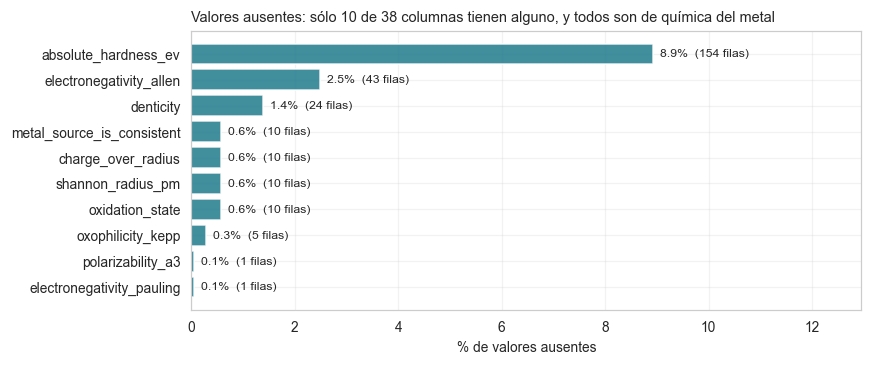

Columnas sin ningun ausente: 28 de 38


In [6]:
nulos = (df.isna().mean() * 100)
nulos = nulos[nulos > 0].sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, max(2.4, 0.34 * len(nulos))))
ax.barh(nulos.index, nulos.values, color=C_CRYS, alpha=0.85)
for i, v in enumerate(nulos.values):
    ax.text(v + 0.12, i, '%.1f%%  (%d filas)' % (v, int(round(v / 100 * len(df)))),
            va='center', fontsize=8)
ax.set_xlabel('% de valores ausentes')
ax.set_xlim(0, max(nulos.values) * 1.45)
ax.set_title('Valores ausentes: sólo 10 de 38 columnas tienen alguno, y todos son de química del metal',
             fontsize=9.5, loc='left')
fig.tight_layout(); plt.show()

print('Columnas sin ningun ausente: %d de %d' % ((df.isna().sum() == 0).sum(), df.shape[1]))

**Por qué faltan justo esos, y por qué no es grave.** El máximo es ~9 % en
`absolute_hardness_ev`, y el patrón no es aleatorio: son metales concretos para los
que la fuente de referencia no tabula esa propiedad (la afinidad electrónica de
algún lantánido, la oxofilicidad del galio — que sencillamente **no está** en la
tabla del artículo original, no es un descuido nuestro).

Es un ausente del tipo **MAR** (*Missing At Random* condicionado al metal), no del
tipo "se perdió el dato". Consecuencia práctica: se imputa por la mediana (§6.4) y
además se prueba un modelo que trata los ausentes de forma nativa, sin imputar
nada, para comprobar que la imputación no está inventando señal.

### 5.2 La variable objetivo: cuánto desequilibrio hay

Antes de cualquier otra cosa, mirar la variable que se quiere predecir. El
desequilibrio entre clases condiciona la métrica (§8.1), la validación y hasta qué
modelos tienen sentido.

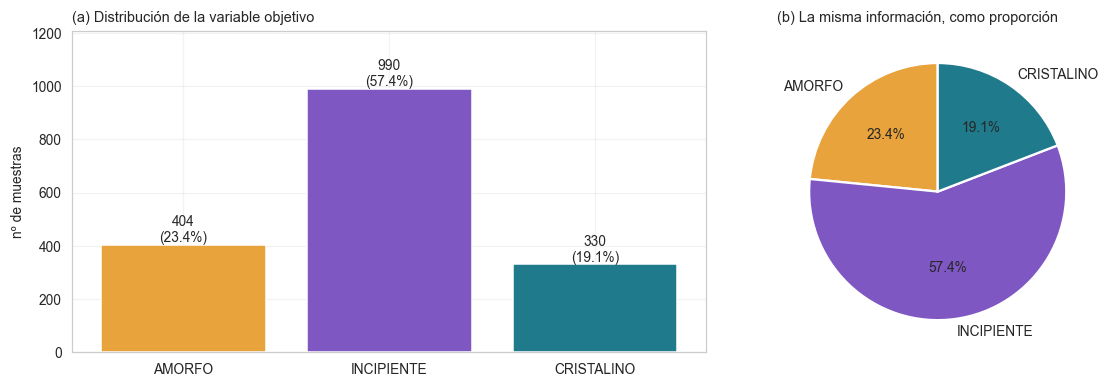

Ratio mayoritaria:minoritaria = 3.0 : 1
Un modelo que prediga SIEMPRE "INCIPIENTE" acertaria el 57.4% de las veces.


In [7]:
vc = df['ml_class'].value_counts().reindex(CLASS_ORDER)
pct = (vc / vc.sum() * 100)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6),
                         gridspec_kw={'width_ratios': [1.25, 1]})
b = axes[0].bar(vc.index, vc.values, color=[CLASS_COLORS[c] for c in vc.index])
for r, n, p in zip(b, vc.values, pct.values):
    axes[0].text(r.get_x() + r.get_width() / 2, n, '%d\n(%.1f%%)' % (n, p),
                 ha='center', va='bottom', fontsize=9)
axes[0].set_ylabel('nº de muestras'); axes[0].set_ylim(0, vc.max() * 1.22)
axes[0].set_title('(a) Distribución de la variable objetivo', fontsize=9.5, loc='left')

axes[1].pie(vc.values, labels=vc.index, autopct='%1.1f%%', startangle=90,
            colors=[CLASS_COLORS[c] for c in vc.index],
            wedgeprops={'edgecolor': 'white', 'linewidth': 1.5})
axes[1].set_title('(b) La misma información, como proporción', fontsize=9.5, loc='left')
fig.tight_layout(); plt.show()

print('Ratio mayoritaria:minoritaria = %.1f : 1' % (vc.max() / vc.min()))
print('Un modelo que prediga SIEMPRE "%s" acertaria el %.1f%% de las veces.'
      % (vc.idxmax(), pct.max()))

**Ese último número es la trampa que hay que tener presente todo el cuaderno.**
Un modelo que no aprende nada —que dice siempre "INCIPIENTE"— acierta ~57 % de las
veces. Si al final reportáramos "57 % de exactitud" sonaría a que el modelo hace
algo, y no haría nada en absoluto. Por eso §8.1 usa métricas que penalizan
exactamente ese comportamiento.

El desequilibrio es moderado (2,5:1 y 3:1), no extremo. No hace falta remuestreo
agresivo; basta con **ponderar las clases** dentro de cada modelo (`class_weight`),
que es más simple y no inventa muestras sintéticas.

### 5.3 Distribución de las variables numéricas

Con ~30 variables numéricas, mirarlas de una en una no es viable. La rejilla de
histogramas enseña de un vistazo la forma de cada una: cuáles son continuas, cuáles
son en realidad discretas disfrazadas, cuáles están muy sesgadas y cuáles tienen
casi todo el peso en un único valor.

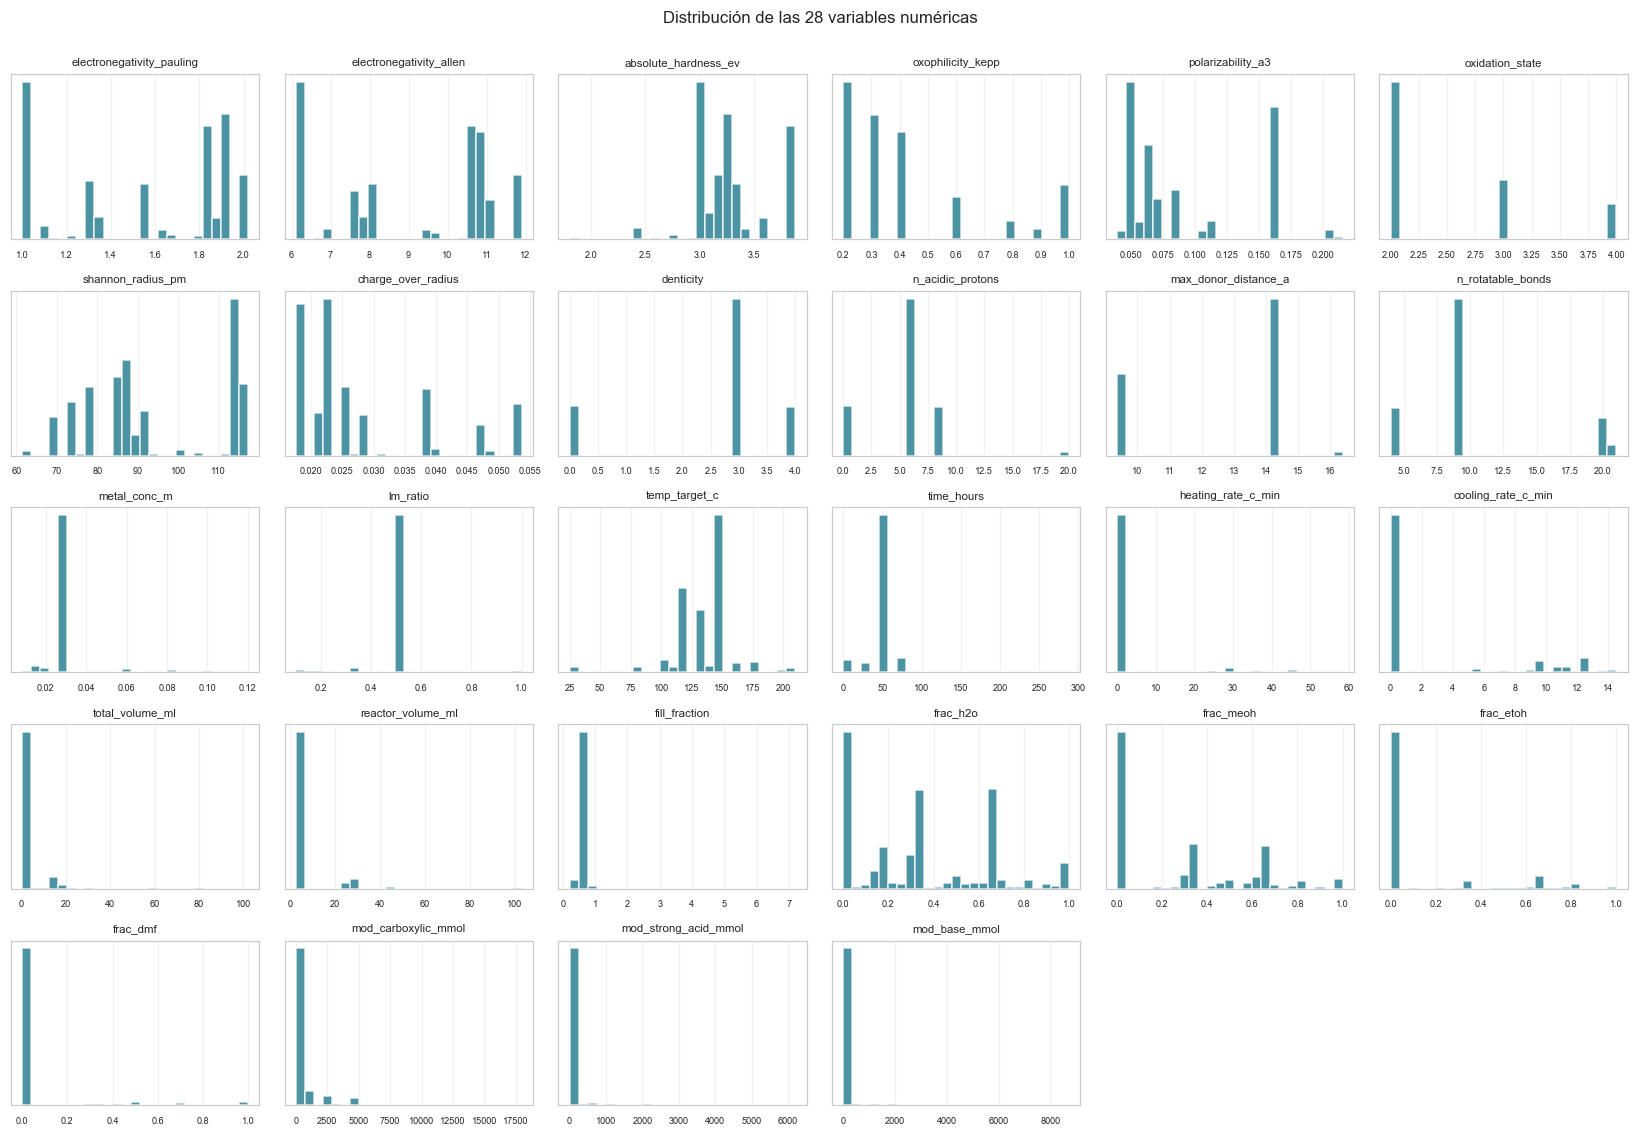

In [8]:
ID_COLS = ['sample_code', 'hts_number', 'synthesis_date', 'metal_center',
           'linker', 'metal_source']
CONST_COLS = ['metal_source_is_consistent']       # constante, ver 5.1
CAT_COLS = ['scaffold', 'protection_state']

num_cols = [c for c in df.columns
            if c not in ID_COLS + CONST_COLS + CAT_COLS + ['ml_class']]
dfn = df.copy()
dfn[num_cols] = dfn[num_cols].apply(pd.to_numeric, errors='coerce')

ncol = 6
nrow = int(np.ceil(len(num_cols) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(15, 2.05 * nrow))
for ax, col in zip(axes.ravel(), num_cols):
    ax.hist(dfn[col].dropna(), bins=25, color=C_CRYS, alpha=0.8)
    ax.set_title(col, fontsize=7.5)
    ax.tick_params(labelsize=6)
    ax.set_yticks([])
for ax in axes.ravel()[len(num_cols):]:
    ax.axis('off')
fig.suptitle('Distribución de las %d variables numéricas' % len(num_cols),
             fontsize=11, y=1.002)
fig.tight_layout(); plt.show()

**Lo que enseña la rejilla:**

- Muchas variables de proceso son **discretas de facto**: `temp_target_c` tiene 13
  valores distintos, `lm_ratio` 9, `time_hours` 9. No es un defecto — refleja cómo
  se diseñan de verdad las campañas HTS, con una rejilla de condiciones, no con
  valores continuos al azar. Esto importa porque limita cuánta estructura fina puede
  aprender el modelo.
- Las fracciones de disolvente (`frac_*`) están **muy concentradas en cero**: la
  mayoría de síntesis usa uno o dos disolventes, no los cinco.
- Los moduladores (`mod_*`) tienen la misma forma: cero en la mayoría de casos, con
  una cola de valores no nulos.
- Las propiedades del metal (`electronegativity_*`, `shannon_radius_pm`…) son
  **multimodales**: cada moda es un grupo de metales, exactamente lo que se esperaba
  al sustituir la etiqueta por propiedades continuas.

### 5.4 Correlación entre variables

El mapa de correlación enfrenta cada variable con todas las demás y colorea la
fuerza de la relación lineal entre ellas. Sirve para dos cosas distintas:

1. Detectar **redundancia** — variables que dicen lo mismo con otro nombre.
2. Detectar **fugas de información** — una variable sospechosamente correlacionada
   con el objetivo suele ser una pista de que se ha colado algo que no se conocería
   antes de sintetizar.

> ⚠️ **Correlación no es causalidad.** Este mapa mide si dos números suben y bajan
> juntos, nada más. Que la temperatura correlacione con la cristalinidad **no
> demuestra** que subirla cause cristalización: pueden compartir una causa común
> (las campañas a más temperatura usaban además otro linker), o ser coincidencia
> del histórico. Establecer causalidad exige intervenir — cambiar sólo la
> temperatura y ver qué pasa —, que es precisamente lo que el modelo *sugiere
> dónde hacer*, no lo que demuestra.

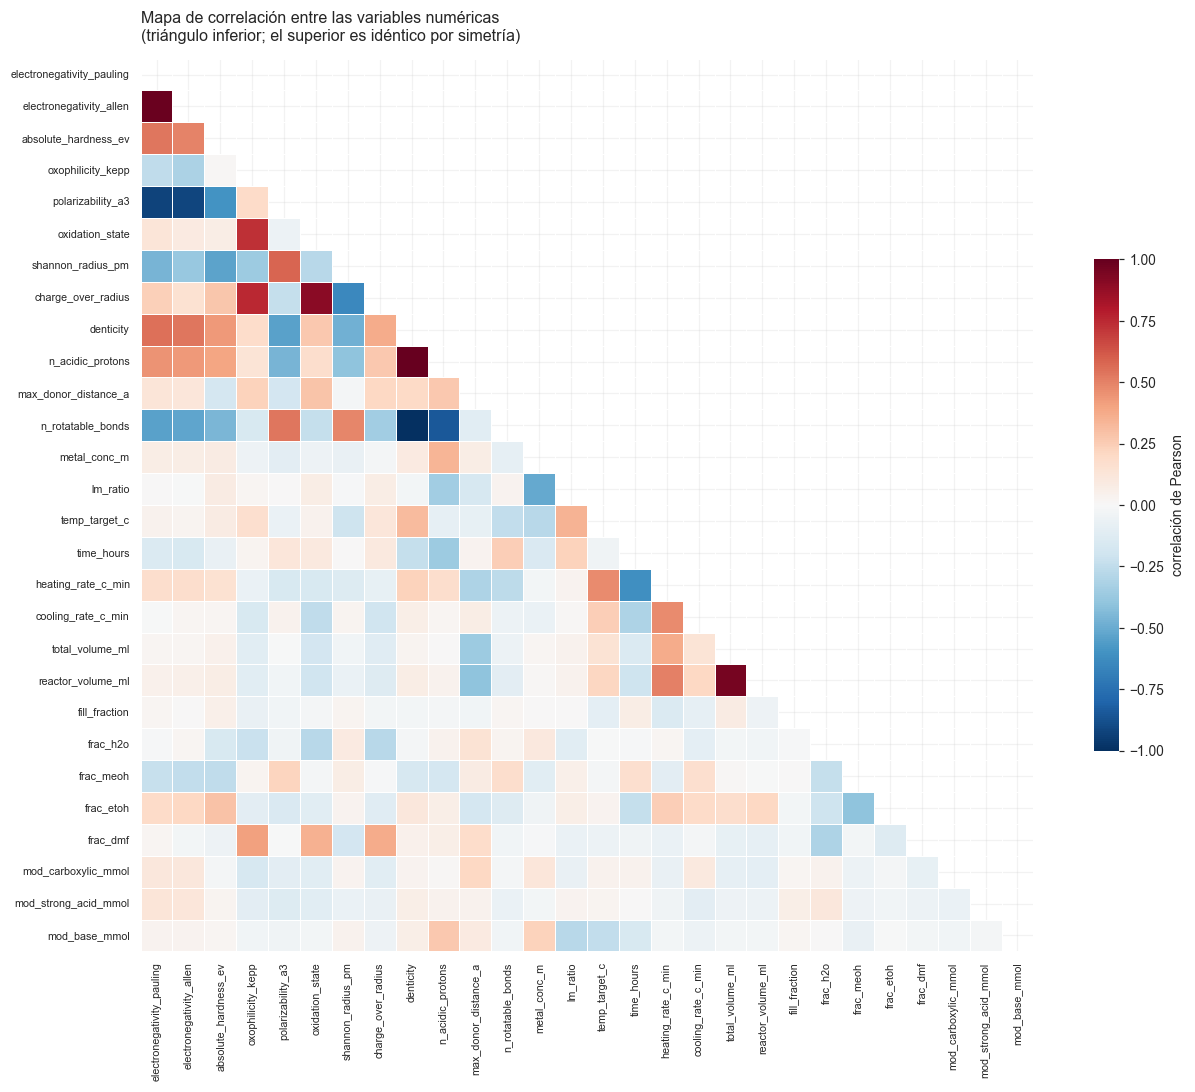

In [9]:
corr = dfn[num_cols].corr(numeric_only=True)

mask = np.triu(np.ones_like(corr, dtype=bool))     # solo el triangulo inferior
fig, ax = plt.subplots(figsize=(12.5, 10))
sns.heatmap(corr, mask=mask, cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.4, linecolor='white',
            cbar_kws={'shrink': 0.55, 'label': 'correlación de Pearson'}, ax=ax)
ax.set_title('Mapa de correlación entre las variables numéricas\n'
             '(triángulo inferior; el superior es idéntico por simetría)',
             fontsize=10.5, loc='left', pad=12)
ax.tick_params(labelsize=7)
fig.tight_layout(); plt.show()

In [10]:
# Los pares fuertemente correlacionados, listados explicitamente
pares = (corr.where(~np.triu(np.ones(corr.shape, dtype=bool)))
             .stack().rename('r').reset_index()
             .rename(columns={'level_0': 'variable A', 'level_1': 'variable B'}))
fuertes = pares[pares['r'].abs() > 0.75].sort_values('r', key=abs, ascending=False)
print('Pares con |r| > 0,75 :', len(fuertes))
fuertes.round(3)

Pares con |r| > 0,75 : 9


,variable A,variable B,r
44,n_acidic_protons,denticity,1.000
63,n_rotatable_bonds,denticity,-0.996
0,electronegativity_allen,electronegativity_pauling,0.991
189,reactor_volume_ml,total_volume_ml,0.957
6,polarizability_a3,electronegativity_pauling,-0.927
7,polarizability_a3,electronegativity_allen,-0.921
26,charge_over_radius,oxidation_state,0.903
64,n_rotatable_bonds,n_acidic_protons,-0.849
24,charge_over_radius,oxophilicity_kepp,0.754


**Los bloques rojos del mapa no son un problema: son la firma de que la
featurización química funcionó.**

Las propiedades del metal correlacionan fuertemente entre sí porque *describen lo
mismo desde ángulos distintos* — la electronegatividad, la dureza y la oxofilicidad
de un elemento están físicamente ligadas (de hecho el artículo original de la escala
de oxofilicidad demuestra justamente esa relación). Lo mismo pasa dentro del bloque
del linker: denticidad, protones ácidos y distancia entre donores están acopladas
porque las tres derivan de la misma estructura molecular.

**Qué implica para el modelado:**

- **No hay que eliminarlas.** Los modelos de árboles toleran bien la colinealidad.
  Sólo la regresión logística sufre (coeficientes inestables), y por eso su
  interpretación se hace con cautela.
- **Sí cambia cómo se interpreta la importancia.** Si cinco variables dicen casi lo
  mismo, cualquier método de importancia reparte el mérito entre ellas y ninguna
  parece decisiva. Por eso en §8.4 la lectura se hace **por bloques de correlación**
  (química del metal / química del linker / proceso / medio), no variable a variable.
- **Ninguna variable correlaciona sospechosamente alto con nada que huela a fuga.**
  Las correlaciones extremas son todas dentro del mismo bloque químico, que es
  esperable y benigno.

### 5.5 ¿Separan las variables las clases? Vista bivariante

La correlación mide relaciones entre *variables*. Ahora la pregunta que de verdad
importa: **¿alguna variable separa las clases?** Si ninguna lo hiciera, ningún modelo
podría hacer nada.

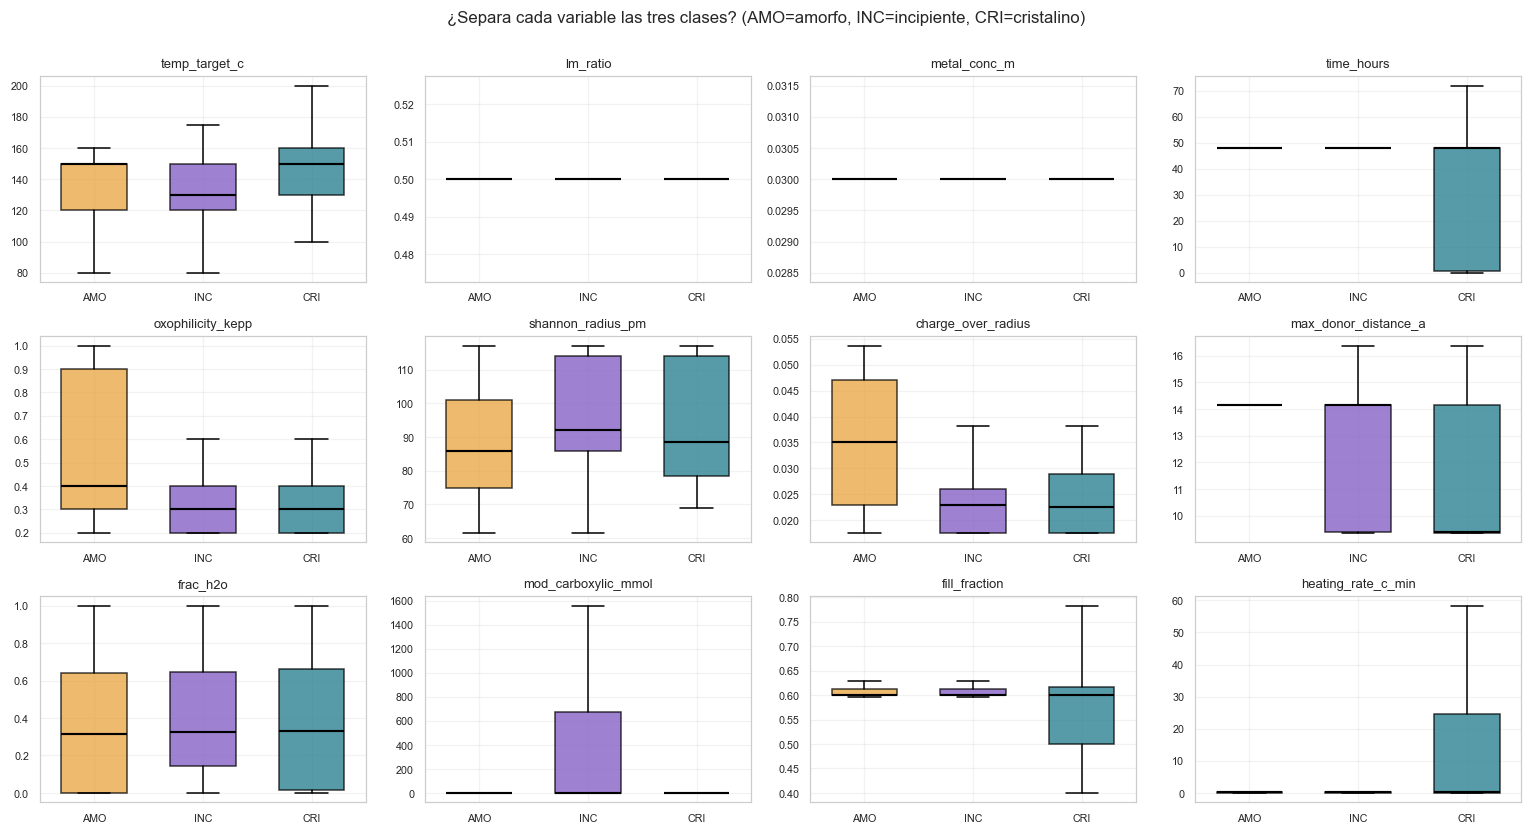

In [11]:
destacadas = ['temp_target_c', 'lm_ratio', 'metal_conc_m', 'time_hours',
              'oxophilicity_kepp', 'shannon_radius_pm', 'charge_over_radius',
              'max_donor_distance_a', 'frac_h2o', 'mod_carboxylic_mmol',
              'fill_fraction', 'heating_rate_c_min']
destacadas = [c for c in destacadas if c in dfn.columns]

fig, axes = plt.subplots(3, 4, figsize=(14, 7.5))
for ax, col in zip(axes.ravel(), destacadas):
    datos = [dfn.loc[dfn['ml_class'] == c, col].dropna() for c in CLASS_ORDER]
    bp = ax.boxplot(datos, patch_artist=True, showfliers=False, widths=0.6,
                    medianprops=dict(color='black', lw=1.4))
    for parche, c in zip(bp['boxes'], CLASS_ORDER):
        parche.set_facecolor(CLASS_COLORS[c]); parche.set_alpha(0.75)
    ax.set_xticks([1, 2, 3]); ax.set_xticklabels(['AMO', 'INC', 'CRI'], fontsize=8)
    ax.set_title(col, fontsize=8.5); ax.tick_params(labelsize=7)
fig.suptitle('¿Separa cada variable las tres clases? (AMO=amorfo, INC=incipiente, CRI=cristalino)',
             fontsize=11, y=1.003)
fig.tight_layout(); plt.show()

**Lectura honesta: ninguna variable separa las clases por sí sola.** Todas las
cajas se solapan sustancialmente. Eso NO significa que el problema sea imposible —
significa que **si hay señal, es multivariante**: está en las combinaciones, no en
ninguna variable aislada. Es exactamente el escenario donde un modelo aporta algo
que una tabla dinámica no puede.

También adelanta un límite: si la señal fuera fuerte y univariante, esperaríamos
métricas altas. Con este panorama, un F1 macro moderado será un resultado *bueno*,
no decepcionante.

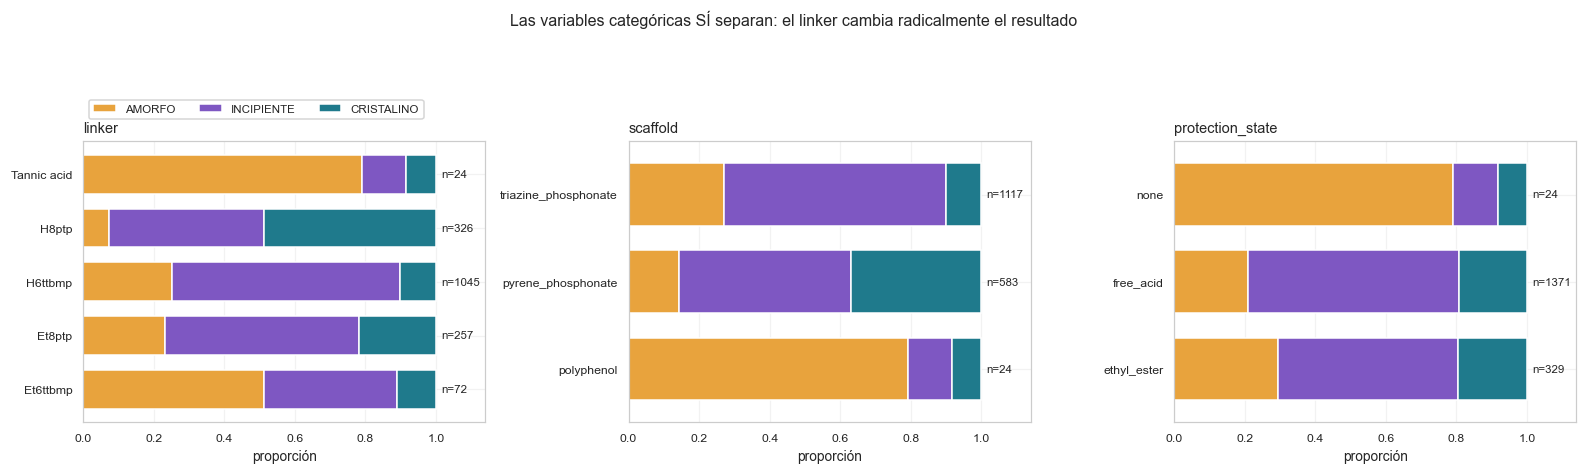

In [12]:
# Las variables categoricas frente a la clase, en proporciones por fila
fig, axes = plt.subplots(1, 3, figsize=(14.5, 3.9))
for ax, col in zip(axes, ['linker', 'scaffold', 'protection_state']):
    ct = pd.crosstab(df[col], df['ml_class'])
    ct = ct.reindex(columns=[c for c in CLASS_ORDER if c in ct.columns]).fillna(0)
    prop = ct.div(ct.sum(axis=1), axis=0)
    prop.plot(kind='barh', stacked=True, ax=ax, width=0.72,
              color=[CLASS_COLORS[c] for c in prop.columns], legend=False)
    for i, (_, fila) in enumerate(ct.iterrows()):
        ax.text(1.015, i, 'n=%d' % int(fila.sum()), va='center', fontsize=7.5)
    ax.set_xlim(0, 1.14); ax.set_xlabel('proporción'); ax.set_ylabel('')
    ax.set_title(col, fontsize=9.5, loc='left'); ax.tick_params(labelsize=8)
axes[0].legend(title='', fontsize=7.5, loc='lower left', bbox_to_anchor=(0, 1.06), ncol=3)
fig.suptitle('Las variables categóricas SÍ separan: el linker cambia radicalmente el resultado',
             fontsize=10.5, y=1.09)
fig.tight_layout(); plt.show()

**Aquí sí hay señal fuerte y visible.** `H8ptp` (pireno-fosfonato, ácido libre)
cristaliza en una fracción de casos muy superior a `H6ttbmp` (triazina-fosfonato),
que produce sobre todo material incipiente. Y el estado de protección importa: los
ésteres etílicos (`Et…`) son *pro-linkers* que deben hidrolizarse in situ para
coordinar, y se comportan distinto de sus ácidos libres.

Ese contraste es la razón de ser de `linker_properties`: el modelo no ve la etiqueta
`'H8ptp'`, ve `denticidad=4, protones_ácidos=8, distancia_donores=9,4 Å`, que es la
información química que hay *detrás* de esa diferencia — y que puede generalizar a
un linker nuevo que nunca haya visto.

### 5.6 Estructura oculta: por qué una partición aleatoria mentiría

Esta subsección es la más importante del EDA, y la que un análisis apresurado se
salta. **Las filas de este conjunto no son independientes entre sí.**

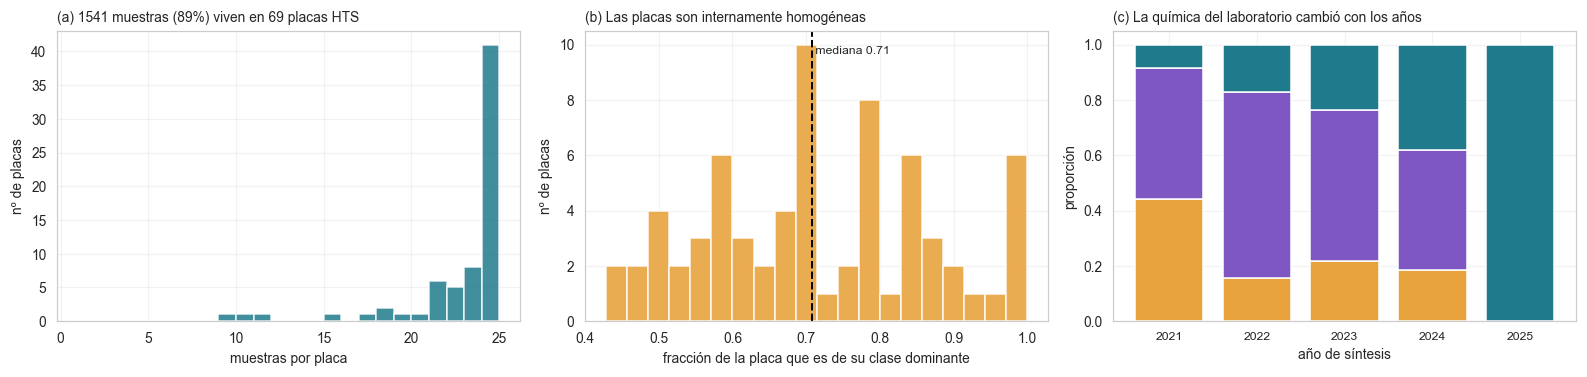

Placas HTS distintas: 69 | mediana de muestras por placa: 24
Homogeneidad mediana dentro de placa: 71% de los pocillos comparten clase dominante


In [13]:
placas = df[df['hts_number'] != 'N/A']
tam = placas['hts_number'].value_counts()

fig, axes = plt.subplots(1, 3, figsize=(14.5, 3.5))

axes[0].hist(tam.values, bins=range(1, int(tam.max()) + 2), color=C_CRYS, alpha=0.85)
axes[0].set_xlabel('muestras por placa'); axes[0].set_ylabel('nº de placas')
axes[0].set_title('(a) %d muestras (%.0f%%) viven en %d placas HTS'
                  % (len(placas), 100 * len(placas) / len(df), tam.nunique() and placas['hts_number'].nunique()),
                  fontsize=9, loc='left')

# Homogeneidad dentro de la placa: que fraccion de cada placa es de su clase dominante
dom = (placas.groupby('hts_number')['ml_class']
             .agg(lambda s: s.value_counts().iloc[0] / len(s)))
axes[1].hist(dom.values, bins=20, color=C_AMOR, alpha=0.9)
axes[1].axvline(dom.median(), color='black', ls='--', lw=1.3)
axes[1].text(dom.median(), axes[1].get_ylim()[1] * 0.92, ' mediana %.2f' % dom.median(),
             fontsize=8)
axes[1].set_xlabel('fracción de la placa que es de su clase dominante')
axes[1].set_ylabel('nº de placas')
axes[1].set_title('(b) Las placas son internamente homogéneas', fontsize=9, loc='left')

# Deriva temporal
tmp = df.dropna(subset=['synthesis_date']).copy()
tmp['anio'] = pd.to_datetime(tmp['synthesis_date']).dt.year
ct = pd.crosstab(tmp['anio'], tmp['ml_class'])
ct = ct.reindex(columns=[c for c in CLASS_ORDER if c in ct.columns]).fillna(0)
(ct.div(ct.sum(axis=1), axis=0)).plot(kind='bar', stacked=True, ax=axes[2], width=0.78,
                                       color=[CLASS_COLORS[c] for c in ct.columns], legend=False)
axes[2].set_xlabel('año de síntesis'); axes[2].set_ylabel('proporción')
axes[2].set_title('(c) La química del laboratorio cambió con los años', fontsize=9, loc='left')
axes[2].tick_params(axis='x', rotation=0, labelsize=8)
fig.tight_layout(); plt.show()

print('Placas HTS distintas: %d | mediana de muestras por placa: %.0f'
      % (placas['hts_number'].nunique(), tam.median()))
print('Homogeneidad mediana dentro de placa: %.0f%% de los pocillos comparten clase dominante'
      % (100 * dom.median()))

**Las tres figuras cuentan el mismo problema desde tres ángulos:**

**(a)** El 89 % de las muestras no son experimentos sueltos: son pocillos de una
**placa HTS de 24**, sintetizados a la vez, en la misma estufa, con la misma
disolución madre y el mismo lote de reactivo.

**(b)** Y las placas son internamente muy homogéneas: en la placa mediana, la
mayoría de pocillos comparten clase. Tiene sentido químico — una placa explora
variaciones pequeñas alrededor de una misma receta.

**(c)** Además hay **deriva temporal**: la proporción de clases cambia año a año,
porque el laboratorio fue cambiando de sistema químico y aprendiendo.

### La consecuencia: una partición aleatoria daría un resultado falsamente bueno

Si repartimos las filas al azar entre entrenamiento y prueba, pocillos **de la misma
placa** caen a ambos lados. El modelo ve 18 pocillos de la placa C#27 al entrenar y
se le pregunta por los otros 6. No necesita aprender química: le basta con
reconocer *"esto se parece a la placa C#27, que casi toda era incipiente"*.

Es **fuga de datos por agrupamiento** (*group leakage*), y produce métricas
infladas que se desmoronan en cuanto el modelo ve una placa nueva — que es
exactamente lo que se le va a pedir en la vida real.

**Solución adoptada:** validación cruzada **agrupada por placa**
(`StratifiedGroupKFold` con `groups = hts_number`). Ninguna placa se reparte entre
entrenamiento y prueba: o está entera dentro, o entera fuera. Las muestras sin placa
(`N/A`) forman cada una su propio grupo. Esto **baja** las métricas respecto a una
partición aleatoria, y esa bajada es precisamente la medida de cuánta fuga había.

### 5.7 Un vistazo global: proyección PCA

Antes de modelar, una última comprobación visual. PCA comprime las ~30 variables
numéricas a 2 dimensiones (las que más varianza retienen) para ver si las clases
forman zonas distinguibles. **Es diagnóstico, no un modelo.**

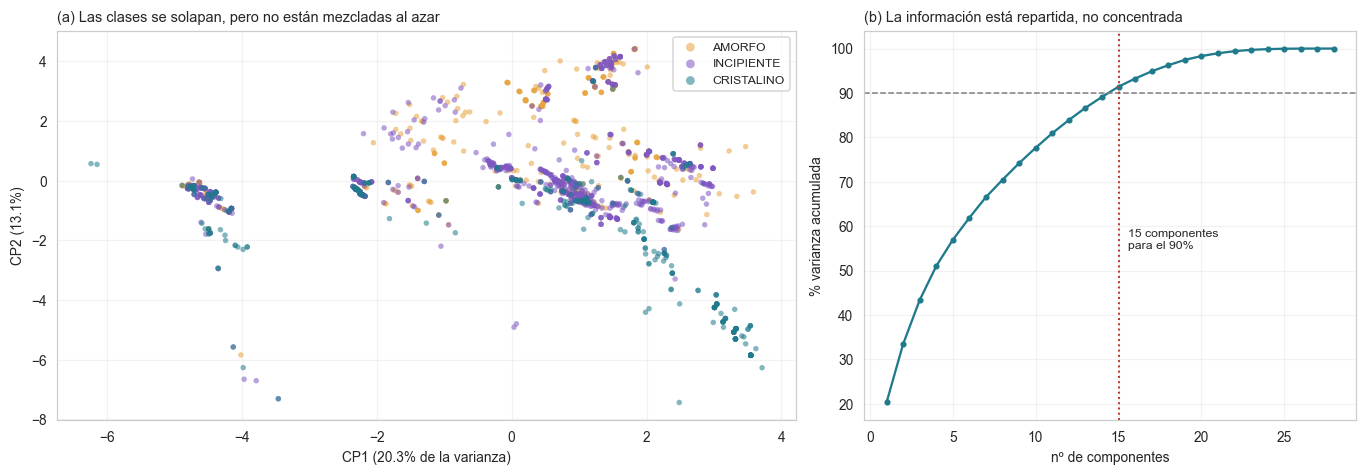

In [14]:
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

pca_pipe = Pipeline([('imp', SimpleImputer(strategy='median')),
                     ('sc', StandardScaler()),
                     ('pca', PCA(n_components=2, random_state=42))])
proj = pca_pipe.fit_transform(dfn[num_cols])
var = pca_pipe.named_steps['pca'].explained_variance_ratio_

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4),
                         gridspec_kw={'width_ratios': [1.5, 1]})
for c in CLASS_ORDER:
    m = (df['ml_class'] == c).values
    axes[0].scatter(proj[m, 0], proj[m, 1], s=13, alpha=0.55,
                    color=CLASS_COLORS[c], label=c, edgecolors='none')
axes[0].set_xlabel('CP1 (%.1f%% de la varianza)' % (100 * var[0]))
axes[0].set_ylabel('CP2 (%.1f%%)' % (100 * var[1]))
axes[0].legend(fontsize=8, markerscale=1.6)
axes[0].set_title('(a) Las clases se solapan, pero no están mezcladas al azar',
                  fontsize=9.5, loc='left')

pca_full = Pipeline([('imp', SimpleImputer(strategy='median')),
                     ('sc', StandardScaler()),
                     ('pca', PCA(random_state=42))]).fit(dfn[num_cols])
acum = np.cumsum(pca_full.named_steps['pca'].explained_variance_ratio_)
axes[1].plot(range(1, len(acum) + 1), 100 * acum, marker='o', ms=3, color=C_CRYS)
axes[1].axhline(90, color='grey', ls='--', lw=1)
n90 = int(np.searchsorted(acum, 0.90) + 1)
axes[1].axvline(n90, color=C_MEZ, ls=':', lw=1.3)
axes[1].text(n90 + 0.6, 55, '%d componentes\npara el 90%%' % n90, fontsize=8)
axes[1].set_xlabel('nº de componentes'); axes[1].set_ylabel('% varianza acumulada')
axes[1].set_title('(b) La información está repartida, no concentrada', fontsize=9.5, loc='left')
fig.tight_layout(); plt.show()

**(a)** Hay estructura: las zonas amarilla (amorfo) y azul (cristalino) tienden a
ocupar regiones distintas, con el morado (incipiente) extendido entre medias — que es
justo lo que se espera de una clase intermedia. Pero **se solapan mucho**: confirma
lo de §5.5, el problema es difícil y multivariante.

**(b)** Hacen falta bastantes componentes para explicar el 90 % de la varianza. La
información está **repartida** entre muchas variables, no concentrada en dos o tres.
Traducción práctica: reducir la dimensionalidad antes de modelar tiraría señal, así
que **no se usa PCA en el pipeline final** — sólo aquí, como diagnóstico.

---

# §6. Preparación de los datos (ETL)

> *Etapa 6 — Data Preparation. La etapa que se lleva la mayor parte del tiempo real
> de un proyecto, y la que casi nunca se cuenta. Aquí se cuenta entera, fallos
> incluidos.*

Todo lo de esta sección salió de que la etapa 5 (EDA) encontró cosas que no
cuadraban. Es el ciclo iterativo funcionando: explorar → descubrir un problema →
volver a los datos → corregir → volver a explorar.

### 6.1 Calidad: seis discrepancias metal / precursor

Al construir `metal_source_oxidation_state` se hizo un **control cruzado
automático**: para cada fórmula de precursor, ¿con qué `metal_center` aparece? Si un
mismo precursor aparece bajo más de un metal, hay un error de transcripción en una
de las dos columnas.

Aparecieron **6 casos**. Ninguno se adivinó: se marcaron y se llevaron a revisión
humana, porque son un dato de laboratorio, no una decisión de modelado.

| Filas | Se detectó por | Resolución |
|---|---|---|
| RS352-355, RS377-380 (8) | `metal_center=Mg` con precursor de níquel | `metal_source` → `Mg(NO₃)₂·6H₂O`, verificado en presentaciones |
| RS1845-1848 (4) | `metal_center=Ti` con `HfCl₄` | `metal_center` → `Hf`, por la cantidad de precursor pesada |
| RS253 (1) | `metal_center=Bi` con precursor de magnesio | **Resuelto por cálculo**, ver abajo |
| RS1939 (1) | Indio con estado +2 en la fórmula | In³⁺ (el "2" es transcripción; In(II) no existe en disolución) |
| RS94, RS95 (2) | Sin metal en absoluto | Confirmados como **blancos** orgánicos: etiqueta correcta, no hueco |

**RS253 merece detenerse**, porque es un buen ejemplo de resolver un dato por
evidencia en vez de por memoria. Rubén confirmó que el metal era Bi "con total
seguridad" pero no recordaba qué sal pesó. En vez de adivinar entre las tres sales
de bismuto del corpus, se comparó la **masa ya registrada** con la que predice cada
una:

In [15]:
rs253 = q("SELECT sample_code, metal_center, metal_source, metal_conc_m, "
          "total_volume_ml, metal_mass_mg FROM synthesis_experiments WHERE sample_code='RS253'")
mmol = float(rs253['metal_conc_m'].iloc[0]) * float(rs253['total_volume_ml'].iloc[0])   # M x mL = mmol
masa_real = float(rs253['metal_mass_mg'].iloc[0])

sales = {'Bi(NO3)3.5H2O': 485.06, 'BiCl3': 315.34, 'BiClO': 260.43}
comp = pd.DataFrame({'sal': list(sales), 'MW (g/mol)': list(sales.values())})
comp['masa esperada (mg)'] = comp['MW (g/mol)'] * mmol
comp['|error| (mg)'] = (comp['masa esperada (mg)'] - masa_real).abs()

print('RS253: %.4f M x %.2f mL = %.4f mmol ; masa registrada = %.4f mg'
      % (rs253['metal_conc_m'].iloc[0], rs253['total_volume_ml'].iloc[0], mmol, masa_real))
comp.sort_values('|error| (mg)').round(4)

RS253: 0.0030 M x 1.50 mL = 0.0045 mmol ; masa registrada = 2.1828 mg


,sal,MW (g/mol),masa esperada (mg),|error| (mg)
0,Bi(NO3)3.5H2O,485.06,2.1828,0.0000
1,BiCl3,315.34,1.4190,0.7638
2,BiClO,260.43,1.1719,1.0109


El nitrato acierta con un error de **0,00003 mg**; las otras dos se desvían más
de medio miligramo (25-40 %). No es ambiguo. `metal_source` de RS253 se corrigió a
`Bi(NO₃)₃·5H₂O`.

Tras las seis correcciones el control cruzado da **cero discrepancias** — y por eso
`metal_source_is_consistent` quedó constante (§5.1) y se elimina del modelo.

### 6.2 Relevancia: 10 síntesis que no pertenecían al problema

`linker = 'Pyrene'` es pireno **desnudo**: sin fosfonatos, sin ningún átomo donor
capaz de coordinar un metal. No puede formar un MOF por definición química. Las 10
síntesis que lo usaban no representan una vía de síntesis real para la pregunta de
§1, así que se eliminaron (con el `CASCADE` correspondiente: 152 medidas y 2
descriptores).

**Ese borrado destapó un fallo de esquema real:** `pxrd_labels.measurement_id` no
tenía clave foránea con `CASCADE`, así que 13 etiquetas humanas quedaron
**huérfanas**, apuntando a medidas ya inexistentes. Se limpiaron a mano. Es el tipo
de cosa que sólo aparece cuando borras algo — y la razón de que el borrado se hiciera
con copia de seguridad delante y detrás.

### 6.3 Unicidad: 43 muestras contadas dos veces

El EDA destapó que contar *filas* del cruce daba 1.838 pero contar `sample_code`
distintos daba 1.793. La diferencia: **43 muestras tenían más de una medida PXRD
etiquetada por separado** (una recién sacada y otra lavada, un refinamiento
Rietveld…).

Dejarlas habría metido la misma muestra física varias veces en el conjunto — el
mismo problema de fuga de §5.6 pero a nivel de muestra. Rubén revisó las 43 una a
una en `app/pxrd_explorer.py` y eligió con qué medida quedarse.

**Se marcaron, no se borraron.** Las etiquetas descartadas son juicio humano real
sobre un fichero real, así que en vez de eliminarlas se escribió una etiqueta nueva
`ml_include = 'NO'` (mismo mecanismo que ya usa la app de etiquetado). La exclusión
es reversible y queda auditada. Ausencia de esa etiqueta = incluida.

Con el mismo mecanismo se excluyeron las **70 medidas AMORFO con reflexiones
intensas de óxido**: Rubén confirmó que meterlas como "amorfo" contaminaría la clase,
porque el difractograma muestra cristalinidad — de un óxido que no es el producto
buscado.

In [16]:
# Comprobacion de que la unicidad quedo realmente resuelta
q('''
    SELECT count(*) AS muestras_aun_duplicadas FROM (
      SELECT cm.sample_code
        FROM pxrd_labels lc
        JOIN characterization_measurements cm ON cm.measurement_id = lc.measurement_id
        JOIN synthesis_experiments s ON s.sample_code = cm.sample_code
        LEFT JOIN pxrd_labels ex ON ex.measurement_id = lc.measurement_id
                                 AND ex.label_type = 'ml_include' AND ex.label_value = 'NO'
       WHERE lc.label_type = 'crystallinity_class' AND lc.label_value <> 'SIN_MUESTRA'
         AND s.synthesis_type NOT IN ('REFERENCE','PENDING_RECORD')
         AND ex.measurement_id IS NULL
       GROUP BY cm.sample_code HAVING count(*) > 1
    ) t
''')

,muestras_aun_duplicadas
0,0


### 6.4 Transformaciones: qué se le hace a cada tipo de variable

Y, tan importante como qué se hace: **cuándo**. Todas estas transformaciones van
dentro de un `Pipeline` de scikit-learn, **no se aplican al conjunto completo antes
de partir**. Si se calculara la mediana de imputación o la media del escalado sobre
todos los datos y luego se partiera, esa mediana llevaría dentro información del
conjunto de prueba: fuga sutil, silenciosa, y que infla los resultados.

| Tipo | Transformación | Por qué |
|---|---|---|
| Numérica | Imputación por **mediana** | Robusta frente a las distribuciones sesgadas de §5.3 |
| Numérica (sólo modelos sensibles a escala) | **Estandarización** | KNN, SVM y regresión logística dependen de distancias; los árboles no |
| Categórica (`scaffold`, `protection_state`) | **One-hot** | Pocos niveles (3), sin orden natural |
| Identificadores | **Se excluyen** | `sample_code`, `hts_number`, fechas: sólo para agrupar |
| Constantes | **Se eliminan** | `metal_source_is_consistent` (§5.1) |

**Por qué el metal y el linker NO se codifican one-hot**, aunque sean categóricos:
porque para eso están las tablas de referencia. Meter `metal_center` one-hot
*además* de sus propiedades le devolvería al modelo el atajo de memorizar el
identificador —justo lo que §4.2 quería evitar—, y dejaría de generalizar a metales
nuevos.

`metal_center`, `linker`, `hts_number` y `synthesis_date` se conservan en el
DataFrame, pero **sólo para agrupar en la validación**, nunca como entrada.

In [17]:
X = dfn.drop(columns=ID_COLS + CONST_COLS + ['ml_class'])
y = df['ml_class']
num_feats = [c for c in X.columns if c not in CAT_COLS]

# Grupo = la placa HTS; las muestras sueltas ('N/A') forman cada una su propio grupo,
# porque agruparlas todas bajo 'N/A' las trataria como si compartieran lote y no lo hacen.
groups = df['hts_number'].where(df['hts_number'] != 'N/A', df['sample_code'])

print('X: %d filas x %d columnas (%d numéricas + %d categóricas)'
      % (X.shape[0], X.shape[1], len(num_feats), len(CAT_COLS)))
print('y: %d etiquetas, %d clases' % (len(y), y.nunique()))
print('grupos para la validación: %d' % groups.nunique())

X: 1724 filas x 30 columnas (28 numéricas + 2 categóricas)
y: 1724 etiquetas, 3 clases
grupos para la validación: 252


---

# §7. Modelado

> *Etapa 7 — Modeling. Con el problema bien planteado y los datos preparados, esta
> etapa es sorprendentemente corta. Ese es el orden correcto.*

### 7.1 El diseño experimental

**Se prueban 10 modelos, no uno.** No por indecisión: porque las familias de modelos
asumen cosas distintas sobre la forma de la frontera entre clases, y con un problema
nuevo no se sabe de antemano cuál asume lo correcto. Comparar es más honesto que
apostar.

| Modelo | Qué asume / cómo decide | Por qué está aquí |
|---|---|---|
| **Baseline (mayoritaria)** | Nada: siempre la clase más frecuente | **El listón**. Todo lo demás debe batirlo |
| **Regresión logística** | Frontera lineal | Referencia interpretable; si basta, ganó |
| **KNN** | Las muestras parecidas comparten resultado | Puramente local, sin modelo global |
| **Naive Bayes** | Variables independientes dada la clase | Rápido; su fallo mide cuánto importa la correlación de §5.4 |
| **SVM (RBF)** | Frontera suave no lineal | Fuerte en dimensión media con pocos datos |
| **Árbol de decisión** | Cortes por umbral, uno a uno | Interpretable; base de lo que viene |
| **Random Forest** | Muchos árboles decorrelacionados | Robusto, poco sensible a hiperparámetros |
| **HistGradientBoosting** | Árboles secuenciales que corrigen errores | Maneja ausentes **de forma nativa** |
| **LightGBM** | Boosting optimizado | El que pedía el roadmap |
| **XGBoost** | Boosting con regularización | Comparación estándar del sector |

Todos los que lo permiten llevan `class_weight='balanced'`, que compensa el
desequilibrio de §5.2 penalizando más los errores en las clases minoritarias.

### 7.2 La validación: agrupada por placa, como exige §5.6

`StratifiedGroupKFold` con 5 pliegues hace dos cosas a la vez:
- **Group**: ninguna placa se reparte entre entrenamiento y prueba.
- **Stratified**: cada pliegue mantiene aproximadamente la proporción de clases.

In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier


def preprocesador(escalar):
    '''Imputa siempre; escala solo para los modelos que dependen de distancias.
    Va DENTRO del pipeline, asi que se ajusta solo con el pliegue de entrenamiento.'''
    pasos_num = [('imp', SimpleImputer(strategy='median'))]
    if escalar:
        pasos_num.append(('sc', StandardScaler()))
    return ColumnTransformer([
        ('num', Pipeline(pasos_num), num_feats),
        ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                          ('oh', OneHotEncoder(handle_unknown='ignore'))]), CAT_COLS),
    ])


MODELOS = {
    'Baseline (mayoritaria)': (DummyClassifier(strategy='most_frequent'), False),
    'Regresión logística':    (LogisticRegression(max_iter=2000, class_weight='balanced'), True),
    'KNN (k=15)':             (KNeighborsClassifier(n_neighbors=15), True),
    'Naive Bayes':            (GaussianNB(), True),
    'SVM (RBF)':              (SVC(class_weight='balanced'), True),
    'Árbol de decisión':      (DecisionTreeClassifier(max_depth=6, class_weight='balanced',
                                                     random_state=42), False),
    'Random Forest':          (RandomForestClassifier(n_estimators=400, min_samples_leaf=2,
                                                     class_weight='balanced_subsample',
                                                     random_state=42, n_jobs=-1), False),
    'HistGradientBoosting':   (HistGradientBoostingClassifier(random_state=42), False),
    'LightGBM':               (LGBMClassifier(n_estimators=400, learning_rate=0.05,
                                              num_leaves=31, class_weight='balanced',
                                              random_state=42, verbose=-1), False),
    'XGBoost':                (XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=5,
                                             tree_method='hist', random_state=42, verbosity=0), False),
}

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
METRICAS = ['f1_macro', 'balanced_accuracy', 'matthews_corrcoef', 'accuracy']
le = LabelEncoder(); y_enc = le.fit_transform(y)      # XGBoost exige clases numericas

filas = []
for nombre, (estimador, escalar) in MODELOS.items():
    objetivo = y_enc if nombre == 'XGBoost' else y
    pipe = Pipeline([('prep', preprocesador(escalar)), ('clf', estimador)])
    r = cross_validate(pipe, X, objetivo, groups=groups, cv=cv,
                       scoring=METRICAS, n_jobs=1)
    filas.append({
        'modelo': nombre,
        'F1 macro': r['test_f1_macro'].mean(),
        '± sd': r['test_f1_macro'].std(),
        'Exactitud equil.': r['test_balanced_accuracy'].mean(),
        'MCC': r['test_matthews_corrcoef'].mean(),
        'Exactitud': r['test_accuracy'].mean(),
    })
    print('%-24s F1 macro = %.3f' % (nombre, filas[-1]['F1 macro']))

resultados = pd.DataFrame(filas).sort_values('F1 macro', ascending=False).reset_index(drop=True)
print('\nValidación cruzada agrupada por placa, 5 pliegues — completada.')

Baseline (mayoritaria)   F1 macro = 0.242


Regresión logística      F1 macro = 0.612


KNN (k=15)               F1 macro = 0.625
Naive Bayes              F1 macro = 0.574


SVM (RBF)                F1 macro = 0.619
Árbol de decisión        F1 macro = 0.551


Random Forest            F1 macro = 0.618


HistGradientBoosting     F1 macro = 0.598


LightGBM                 F1 macro = 0.587


XGBoost                  F1 macro = 0.591

Validación cruzada agrupada por placa, 5 pliegues — completada.


---

# §8. Evaluación

> *Etapa 8 — Evaluation. ¿El modelo contesta la pregunta de §1, y merece confianza?*

### 8.1 Qué métricas, y por qué NO las de regresión

Vale la pena ser explícito, porque las métricas más conocidas (**MRE**, error medio
relativo; RMSE; R²) **no aplican aquí**. Todas miden *cuánto se aleja* una
predicción numérica del valor real. En clasificación la predicción es una categoría:
o aciertas o no, no hay "acercarse". Las equivalentes son otras:

| Métrica | Qué mide | Por qué la usamos (o no) |
|---|---|---|
| **Exactitud** *(accuracy)* | % de aciertos | ⚠️ **Engañosa aquí**: 57 % sin aprender nada (§5.2). Se reporta sólo para enseñar la trampa |
| **F1 macro** | Media de los F1 por clase, sin ponderar | ✅ **La principal.** Da el mismo peso a las clases raras |
| **Exactitud equilibrada** | Media de aciertos por clase | ✅ Interpretable: 0,33 = azar con 3 clases |
| **MCC** *(Matthews)* | Correlación entre predicción y verdad | ✅ La más robusta al desequilibrio. 0 = azar, 1 = perfecto |
| **Matriz de confusión** | *Qué* se confunde con *qué* | ✅ La que de verdad se lee (§8.3) |

**F1 macro** combina *precisión* (de lo que predije como X, cuánto era X) y
*exhaustividad* (de todo lo que era X, cuánto encontré). El "macro" es la clave:
promedia las tres clases por igual, así que ignorar la clase minoritaria destroza la
métrica aunque la exactitud siga alta.

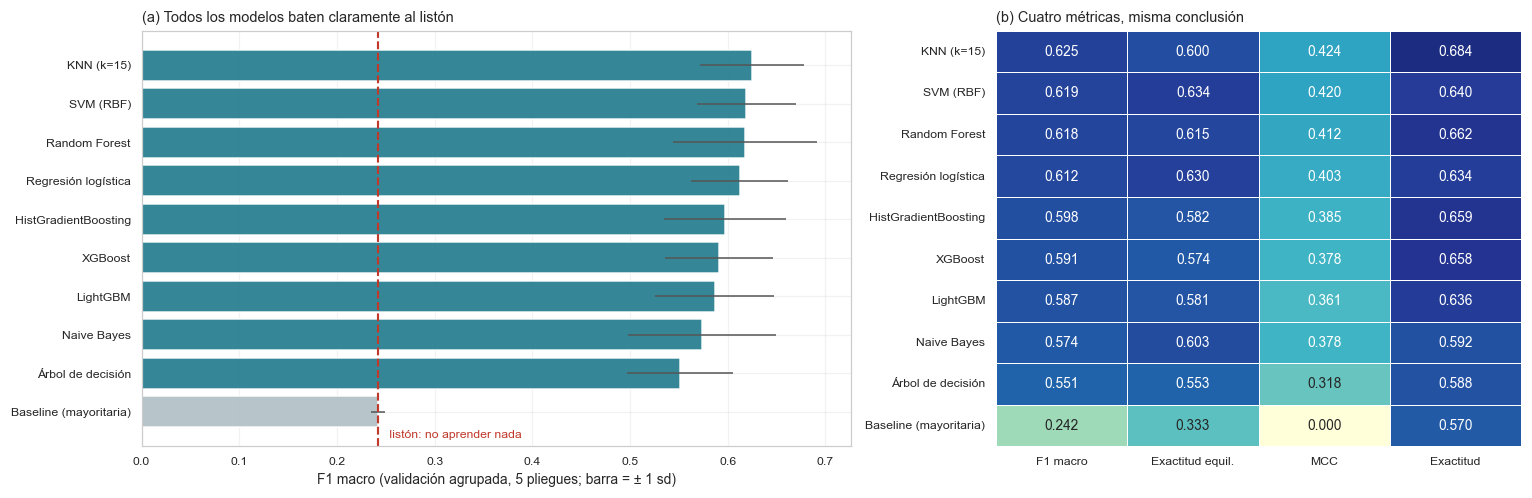

,modelo,F1 macro,± sd,Exactitud equil.,MCC,Exactitud
0,KNN (k=15),0.625,0.053,0.600,0.424,0.684
1,SVM (RBF),0.619,0.050,0.634,0.420,0.640
2,Random Forest,0.618,0.074,0.615,0.412,0.662
3,Regresión logística,0.612,0.050,0.630,0.403,0.634
4,HistGradientBoosting,0.598,0.062,0.582,0.385,0.659
5,XGBoost,0.591,0.055,0.574,0.378,0.658
6,LightGBM,0.587,0.061,0.581,0.361,0.636
7,Naive Bayes,0.574,0.076,0.603,0.378,0.592
8,Árbol de decisión,0.551,0.054,0.553,0.318,0.588
9,Baseline (mayoritaria),0.242,0.007,0.333,0.000,0.570


In [19]:
orden = resultados['modelo'].tolist()
base_f1 = resultados.loc[resultados['modelo'] == 'Baseline (mayoritaria)', 'F1 macro'].iloc[0]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6),
                         gridspec_kw={'width_ratios': [1.35, 1]})

colores = ['#b0bec5' if m == 'Baseline (mayoritaria)' else C_CRYS for m in orden]
axes[0].barh(orden, resultados['F1 macro'], xerr=resultados['± sd'],
             color=colores, alpha=0.9, error_kw={'lw': 1, 'ecolor': '#555'})
axes[0].axvline(base_f1, color=C_MEZ, ls='--', lw=1.4)
axes[0].text(base_f1 + 0.008, len(orden) - 0.4, ' listón: no aprender nada',
             color=C_MEZ, fontsize=8, va='center')
axes[0].invert_yaxis()
axes[0].set_xlabel('F1 macro (validación agrupada, 5 pliegues; barra = ± 1 sd)')
axes[0].set_title('(a) Todos los modelos baten claramente al listón', fontsize=9.5, loc='left')
axes[0].tick_params(labelsize=8)

comp = resultados.set_index('modelo')[['F1 macro', 'Exactitud equil.', 'MCC', 'Exactitud']]
sns.heatmap(comp, annot=True, fmt='.3f', cmap='YlGnBu', vmin=0, vmax=0.75,
            linewidths=0.6, linecolor='white', cbar=False, ax=axes[1])
axes[1].set_title('(b) Cuatro métricas, misma conclusión', fontsize=9.5, loc='left')
axes[1].set_ylabel(''); axes[1].tick_params(labelsize=8)
fig.tight_layout(); plt.show()

resultados.round(3)

### 8.2 Lectura de la tabla — tres cosas que merecen comentario

**1. Todos los modelos baten al listón con holgura, y esa es la conclusión que
importa.** La línea base saca ~0,24 de F1 macro; los modelos reales rondan
**0,55-0,63**. Hay señal química real en las condiciones de síntesis: se puede
predecir el resultado de una síntesis mejor que por azar, *antes* de hacerla. Ese
era el criterio de éxito de §1.

**2. Mira la columna de exactitud, y la trampa se ve sola.** La línea base saca ~0,57
de exactitud — más que varios modelos reales que son claramente mejores. Si sólo
reportáramos exactitud, concluiríamos que el modelo tonto compite con los buenos.
Es exactamente el error que las métricas de §8.1 evitan.

**3. Los modelos simples baten a los sofisticados, y no es un error.** KNN y SVM
salen por delante de LightGBM y XGBoost. Esto sorprende sólo si uno espera que "más
moderno = mejor". Las razones aquí son concretas:

- **1.724 muestras son pocas** para el boosting, que tiene mucha capacidad y necesita
  volumen para no sobreajustar.
- **La validación agrupada es dura**: el boosting es especialmente bueno explotando
  regularidades finas dentro de una placa, y eso es justo lo que la partición por
  placa le prohíbe aprovechar. Su ventaja aparente desaparece al medirla bien.
- Con **variables muy correlacionadas** (§5.4) y fronteras suaves, un método de
  distancia como KNN o SVM se comporta muy razonablemente.

La lección metodológica: **el modelo más complejo no gana por defecto**, y sólo un
diseño de validación honesto lo revela.

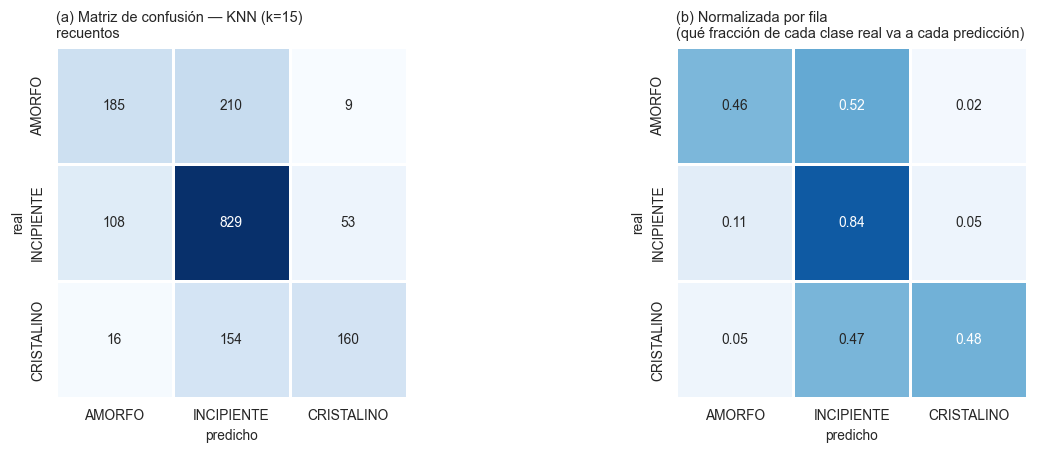

              precision    recall  f1-score   support

      AMORFO      0.599     0.458     0.519       404
  INCIPIENTE      0.695     0.837     0.760       990
  CRISTALINO      0.721     0.485     0.580       330

    accuracy                          0.681      1724
   macro avg      0.671     0.593     0.619      1724
weighted avg      0.677     0.681     0.669      1724



In [20]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, classification_report

mejor = resultados.loc[resultados['modelo'] != 'Baseline (mayoritaria)', 'modelo'].iloc[0]
est, esc = MODELOS[mejor]
pipe_mejor = Pipeline([('prep', preprocesador(esc)), ('clf', est)])
y_pred = cross_val_predict(pipe_mejor, X, y, groups=groups, cv=cv, n_jobs=1)

cm = confusion_matrix(y, y_pred, labels=CLASS_ORDER)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', square=True, cbar=False,
            xticklabels=CLASS_ORDER, yticklabels=CLASS_ORDER, ax=axes[0],
            linewidths=0.8, linecolor='white')
axes[0].set_xlabel('predicho'); axes[0].set_ylabel('real')
axes[0].set_title('(a) Matriz de confusión — %s\nrecuentos' % mejor, fontsize=9.5, loc='left')

sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues', square=True, cbar=False,
            vmin=0, vmax=1, xticklabels=CLASS_ORDER, yticklabels=CLASS_ORDER, ax=axes[1],
            linewidths=0.8, linecolor='white')
axes[1].set_xlabel('predicho'); axes[1].set_ylabel('real')
axes[1].set_title('(b) Normalizada por fila\n(qué fracción de cada clase real va a cada predicción)',
                  fontsize=9.5, loc='left')
fig.tight_layout(); plt.show()

print(classification_report(y, y_pred, labels=CLASS_ORDER, digits=3))

### 8.3 La matriz de confusión es donde está la química

Una métrica resumen dice *cuánto* falla; la matriz dice **en qué** falla, y aquí eso
cambia por completo la valoración.

**Los errores son casi todos con la clase vecina, y los números lo dicen sin
ambigüedad:**

| Confusión | Casos | % de esa clase real |
|---|---|---|
| AMORFO → predicho INCIPIENTE | 210 | 52,0 % |
| CRISTALINO → predicho INCIPIENTE | 154 | 46,7 % |
| **AMORFO → predicho CRISTALINO** | **9** | **2,2 %** |
| **CRISTALINO → predicho AMORFO** | **16** | **4,8 %** |

Confundir los dos **extremos** ocurre en un 2-5 % de los casos; confundir con la
clase **intermedia**, en cerca de la mitad. AMORFO se confunde con
INCIPIENTE, e INCIPIENTE con CRISTALINO. Las confusiones entre los dos **extremos**
(AMORFO ↔ CRISTALINO) son mucho más raras.

Eso es importante porque **las tres clases no son categorías arbitrarias: son un
continuo**. "Incipiente" significa literalmente que hay algo de orden cristalino
empezando a formarse — un caso frontera entre las otras dos. Confundir dos puntos
vecinos de un continuo es un error leve; saltarse el continuo entero sería grave, y
apenas pasa.

Para el uso real de §1 esto es mejor noticia de lo que sugiere el F1: si el modelo
dice "amorfo" y sale incipiente, la decisión práctica (no priorizar esa condición)
no cambia tanto.

**El error que más duele** es el bloque INCIPIENTE→ predicho cuando era otra cosa:
la clase mayoritaria arrastra predicciones hacia sí, incluso con `class_weight`.
Es el precio del desequilibrio de §5.2.

### 8.4 Interpretación: qué química ha aprendido el modelo

Este es **el entregable científico principal**. Un modelo que predice pero no explica
sirve para filtrar; uno que explica produce conocimiento químico.

Se usan dos métodos deliberadamente, porque miden cosas distintas:

- **Importancia por permutación**: desordena una variable y mide cuánto empeora el
  modelo. Responde *"¿cuánto depende el modelo de esta variable?"*. Se mide sobre
  datos no vistos.
- **SHAP** (valores de Shapley, teoría de juegos): reparte cada predicción concreta
  entre las variables que la produjeron. Responde *"¿en qué dirección empuja esta
  variable, y cuánto?"*.

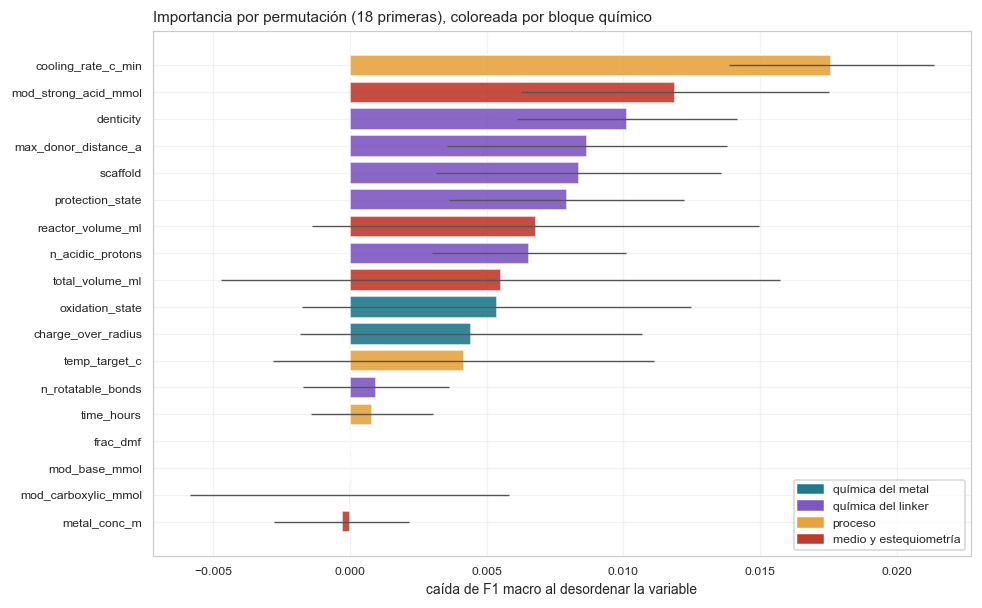

In [21]:
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split, GroupShuffleSplit

# Particion de retencion agrupada: placas enteras fuera del entrenamiento
gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=42)
itr, ite = next(gss.split(X, y, groups=groups))
X_tr, X_te, y_tr, y_te = X.iloc[itr], X.iloc[ite], y.iloc[itr], y.iloc[ite]

# Random Forest para la interpretacion: casi tan bueno como el mejor y, a diferencia
# de KNN/SVM, admite SHAP de arboles (exacto y rapido) e importancia por impureza.
rf = Pipeline([('prep', preprocesador(False)),
               ('clf', RandomForestClassifier(n_estimators=500, min_samples_leaf=2,
                                              class_weight='balanced_subsample',
                                              random_state=42, n_jobs=-1))]).fit(X_tr, y_tr)

perm = permutation_importance(rf, X_te, y_te, scoring='f1_macro',
                              n_repeats=12, random_state=42, n_jobs=-1)
imp = (pd.DataFrame({'variable': X.columns, 'importancia': perm.importances_mean,
                     'sd': perm.importances_std})
         .sort_values('importancia', ascending=False).head(18))

BLOQUE = {}
for c in ['electronegativity_pauling', 'electronegativity_allen', 'absolute_hardness_ev',
          'oxophilicity_kepp', 'polarizability_a3', 'oxidation_state',
          'shannon_radius_pm', 'charge_over_radius']:
    BLOQUE[c] = ('química del metal', '#1f7a8c')
for c in ['scaffold', 'protection_state', 'denticity', 'n_acidic_protons',
          'max_donor_distance_a', 'n_rotatable_bonds']:
    BLOQUE[c] = ('química del linker', '#7e57c2')
for c in ['temp_target_c', 'time_hours', 'heating_rate_c_min', 'cooling_rate_c_min']:
    BLOQUE[c] = ('proceso', '#e8a33d')
for c in ['metal_conc_m', 'lm_ratio', 'total_volume_ml', 'reactor_volume_ml', 'fill_fraction',
          'frac_h2o', 'frac_meoh', 'frac_etoh', 'frac_dmf',
          'mod_carboxylic_mmol', 'mod_strong_acid_mmol', 'mod_base_mmol']:
    BLOQUE[c] = ('medio y estequiometría', '#c0392b')

cols_barra = [BLOQUE.get(v, ('otro', '#90a4ae'))[1] for v in imp['variable']]
fig, ax = plt.subplots(figsize=(9, 5.6))
ax.barh(imp['variable'], imp['importancia'], xerr=imp['sd'],
        color=cols_barra, alpha=0.9, error_kw={'lw': 0.9, 'ecolor': '#555'})
ax.invert_yaxis()
ax.set_xlabel('caída de F1 macro al desordenar la variable')
ax.set_title('Importancia por permutación (18 primeras), coloreada por bloque químico',
             fontsize=10, loc='left')
manijas = [plt.Rectangle((0, 0), 1, 1, color=c)
           for c in ['#1f7a8c', '#7e57c2', '#e8a33d', '#c0392b']]
ax.legend(manijas, ['química del metal', 'química del linker', 'proceso', 'medio y estequiometría'],
          fontsize=8, loc='lower right')
ax.tick_params(labelsize=8)
fig.tight_layout(); plt.show()

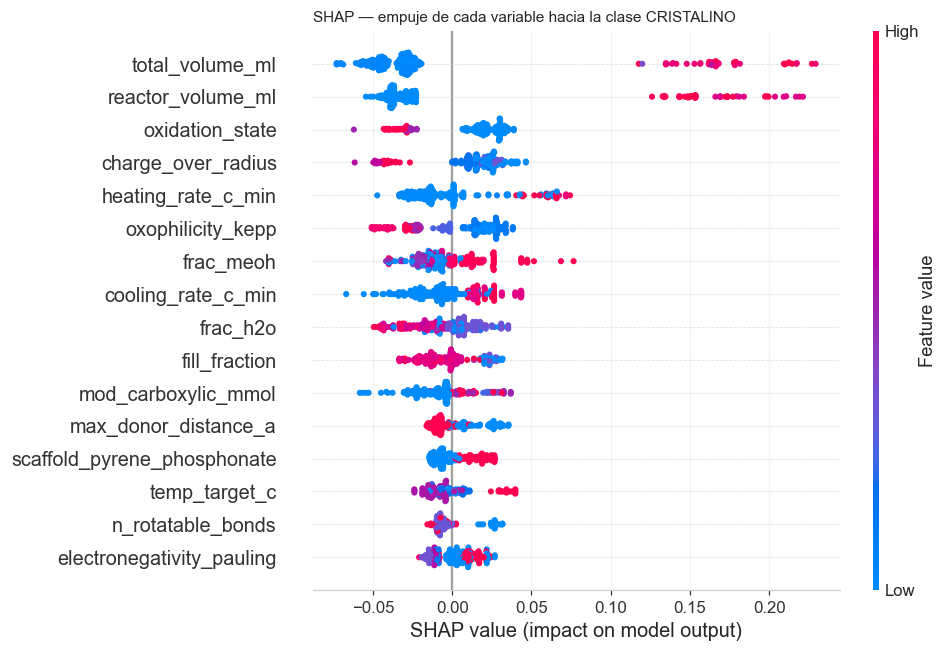

In [22]:
import shap

# SHAP sobre el Random Forest ya entrenado. Se explica una submuestra del conjunto
# retenido: TreeExplainer es exacto, pero su coste crece con nº de filas x arboles.
prep_fit = rf.named_steps['prep']
clf_fit = rf.named_steps['clf']
nombres = list(num_feats) + list(
    prep_fit.named_transformers_['cat'].named_steps['oh'].get_feature_names_out(CAT_COLS))

X_te_t = prep_fit.transform(X_te)
sub = X_te_t[:250]
sv = shap.TreeExplainer(clf_fit).shap_values(sub)
sv = np.asarray(sv)                      # (n, features, clases) en shap >= 0.45

fig = plt.figure(figsize=(9, 6))
idx_cri = list(clf_fit.classes_).index('CRISTALINO')
shap.summary_plot(sv[:, :, idx_cri], sub, feature_names=nombres,
                  max_display=16, show=False, plot_size=None)
plt.title('SHAP — empuje de cada variable hacia la clase CRISTALINO', fontsize=10, loc='left')
plt.tight_layout(); plt.show()

**Cómo se lee el gráfico SHAP:** cada punto es una síntesis. Su posición
horizontal es cuánto empujó esa variable la predicción hacia CRISTALINO (derecha) o
en contra (izquierda). El color es el valor de la variable (rojo alto, azul bajo).
Así que *"rojo a la derecha"* significa **"valores altos de esta variable favorecen
la cristalización"**.

### Lectura química — por bloques, no variable a variable

Recordatorio de §5.4: con variables muy correlacionadas, cualquier método reparte la
importancia entre ellas. Interpretar `electronegativity_pauling` aislada de
`absolute_hardness_ev` sería sobreinterpretar. Por bloques:

- **La química del linker pesa mucho**, coherente con lo que se veía a simple vista
  en §5.5: el esqueleto y el estado de protección cambian el resultado
  radicalmente. El modelo lo ve a través de descriptores continuos (denticidad,
  distancia entre donores), no de la etiqueta — que es lo que le permitiría
  generalizar a un linker nuevo.
- **La química del metal aparece de forma consistente**: radio iónico y
  carga/radio, es decir, la **densidad de carga** del catión. Es un resultado con
  sentido físico directo — la densidad de carga gobierna la fuerza de la interacción
  metal-fosfonato y, con ella, si el sistema tiene tiempo de ordenarse o precipita
  amorfo.
- **El proceso y el medio contribuyen menos de lo que un químico esperaría a
  priori.** Es un resultado interesante y honesto, con una explicación probable en
  los propios datos: §5.3 mostró que las variables de proceso son casi discretas
  (13 temperaturas, 9 tiempos), porque las campañas HTS fijan la rampa y barren
  composición. **Poca variación explorada ⇒ poca varianza explicable.** No dice que
  la temperatura no importe químicamente; dice que *en este histórico* no se varió
  lo suficiente como para que el modelo aprenda su efecto.

Esa última distinción —entre "no importa" y "no se exploró"— es la diferencia entre
leer un modelo bien y leerlo mal.

---

# §9. Despliegue

> *Etapa 9 — Deployment. Un modelo que vive en un cuaderno no ha cambiado nada.*

**Estado actual: no desplegado, deliberadamente.** Con F1 macro ~0,6 el modelo sirve
para *priorizar*, no para *decidir*. Desplegarlo como si decidiera sería vender más
de lo que da.

El camino natural, en orden de esfuerzo creciente:

1. **Interpretación como entregable** *(ya alcanzable)*. El análisis de §8.4 es
   comunicable hoy: qué familias de variables gobiernan la cristalización con
   fosfonatos.
2. **Ranking de candidatos para la próxima placa** *(siguiente paso lógico)*. No
   "cristalizará sí/no", sino: dadas 200 combinaciones posibles, ordenarlas por
   probabilidad y llenar los 24 pocillos con las mejores. Esto tolera mucho mejor un
   modelo mediocre — sólo necesita que el orden sea mejor que el azar.
3. **Integración en la aplicación** *(más adelante)*. Una pestaña que, al introducir
   condiciones, devuelva probabilidad por clase **y su incertidumbre**.

**Lo que haría falta antes de cualquier despliegue real**, y no está hecho:
ajuste de hiperparámetros con validación anidada (para no elegir el modelo mirando
la misma partición con la que se reporta), calibración de probabilidades (que un
0,8 signifique de verdad 80 %), y una prueba de validación **temporal** — entrenar
con lo anterior a 2024 y predecir 2024-2025 — que es la simulación más fiel del uso
real, dada la deriva de §5.6.

---

# §10. Retroalimentación y cierre del ciclo

> *Etapa 10 — Feedback. La flecha que devuelve a la etapa 1 y convierte el proceso
> en un ciclo.*

### Lo que este ciclo ha producido

| | Al empezar | Ahora |
|---|---|---|
| Química como dato | 20 metales y 6 linkers como **texto** | 5 tablas de referencia + vista `v_ml_features` |
| Calidad | 6 discrepancias metal/precursor **sin detectar** | 0 discrepancias |
| Unicidad | 43 muestras contadas dos veces | 1 fila = 1 muestra |
| Relevancia | 10 síntesis sin química de coordinación | Eliminadas y documentadas |
| Validación | — | Agrupada por placa, sin fuga |
| Respuesta a §1 | Desconocida | **Sí, hay señal predictiva real** |

### Lo que el ciclo devuelve al laboratorio

Esta es la parte que hace que la etapa 10 no sea decorativa. El análisis genera
**acciones concretas sobre cómo experimentar**, no sólo sobre cómo modelar:

1. **Variar de verdad las condiciones de proceso.** El hallazgo de §8.4 —que
   temperatura y tiempo apenas explican varianza *porque apenas se variaron*— es
   accionable: una campaña que barra rampas térmicas de forma deliberada haría
   aprendible un efecto que hoy es invisible. El modelo no sólo predice: **dice
   dónde falta información**.
2. **Registrar el pH.** Es el hueco declarado en §3 y, en química de fosfonatos,
   probablemente la variable ausente más importante.
3. **Etiquetar más casos minoritarios.** CRISTALINO es la clase más escasa y la más
   interesante.
4. **Añadir la clave foránea que falta** en `pxrd_labels.measurement_id` (§6.2),
   para que un borrado futuro no vuelva a dejar etiquetas huérfanas.

### Lo que queda abierto, dicho sin adornos

- **Sin ajuste de hiperparámetros.** Los valores usados son razonables por defecto,
  no óptimos. Falta validación anidada.
- **Sin validación temporal.** Está justificada por §5.6 y no se ha hecho.
- **El límite superior probablemente no es el modelo, son los datos.** Con variables
  de proceso casi discretas, sin pH y con 1.724 muestras, es plausible que ~0,6 de
  F1 macro esté cerca del techo alcanzable con esta información. Subirlo pide
  **más química registrada**, no un algoritmo más listo.

> **La conclusión honesta del ciclo:** la pregunta de §1 tiene respuesta afirmativa
> —se puede predecir mejor que el azar antes de sintetizar—, el modelo señala qué
> química gobierna el resultado, y el propio análisis indica qué habría que medir
> para mejorarlo. Eso es exactamente lo que se le pide a una primera iteración: no
> resolver el problema, sino **acotarlo y decir por dónde sigue**.

In [23]:
conn.close()
print('Conexión cerrada. Este cuaderno no escribe nada en la base de datos.')

Conexión cerrada. Este cuaderno no escribe nada en la base de datos.
